# Análise exploratória de dados (EDA) dos chunks da coleção *500 Perguntas, 500 Respostas*

**O que é uma análise exploratória?** É o primeiro contato "de verdade" com os dados, antes de
usar eles num modelo. A ideia é responder perguntas simples, mas que evitam surpresas depois:

- Quantos registros existem? Quais colunas? Tem valor faltando?
- Como os dados se distribuem (por livro, por ano, por capítulo)?
- Qual o tamanho dos textos? Algum passa do limite do modelo de embedding?
- Tem coisa repetida, estranha ou quebrada?

**Os dados:** o arquivo `codigo/data/processed/chunks.jsonl`. Cada linha é um *chunk*, isto é, um
pedaço de texto que vai virar um vetor no índice do RAG. Cada chunk é um par **pergunta +
resposta** de um dos 41 livros da Embrapa. Respostas muito longas foram divididas em mais de um
chunk (até 512 tokens cada).

**Filtro do corpus (14/11/2026):** por decisão do orientador, o corpus tem por enquanto só os pares
que vêm de texto. Ficaram de fora as introduções dos livros e as perguntas cuja resposta dependia
de uma imagem (transcrita com IA, ou não transcrita). O corpus completo continua em
`codigo/data/processed/auxiliares/chunks_completo.jsonl`, e a seção 10 mostra o que saiu.

**Como rodar:** este notebook precisa só de `pandas` e `matplotlib`
(`pip install pandas matplotlib`). Se o pacote `tokenizers` estiver instalado e o tokenizador do
`multilingual-e5-small` estiver em cache, a seção de tokens usa a contagem exata; senão, usa uma
estimativa.

**Roteiro**
1. Carregar e conhecer as colunas
2. Tipos de chunk e chunks divididos
3. Os livros: culturas, anos, formatos, edições
4. Perguntas: estão todas lá?
5. Capítulos e temas
6. Tamanho dos textos (caracteres, palavras, tokens)
7. Como as perguntas são feitas
8. Vocabulário
9. Repetições
10. O que ficou fora do corpus
11. Autores
12. Resumo dos achados

## Resumo dos achados

Os principais resultados desta análise, antes dos detalhes (números do corpus filtrado de 14/11/2026):

- **Tamanho:** 20.665 chunks, que correspondem a 20.381 perguntas de 41 livros. Todos são pares
  pergunta-resposta vindos de texto.
- **O que ficou fora:** 222 chunks do corpus completo. São 96 introduções, 113 perguntas com imagem
  transcrita por IA (121 chunks) e 5 perguntas que dependiam de uma tabela ou figura não transcrita.
  As perguntas com imagem estão espalhadas por 32 livros (seção 10).
- **Qualidade:** não há resposta vazia nem campo faltando. A única falha de extração é a pergunta 383
  do livro de búfalos (seção 4).
- **Equilíbrio:** cada livro tem de 492 a 559 chunks, então nenhuma cultura domina o índice (seção 3).
- **Tamanho dos textos:** os chunks são curtos (mediana de 86 palavras e 147 tokens). Nenhum passa de
  512 tokens, e só 267 perguntas (1,3%) precisaram ser divididas em partes (seções 2 e 6).
- **Idade das fontes:** a maioria dos livros é de 2013 (de 2005 a 2023), então algumas recomendações
  podem estar desatualizadas (seção 3).
- **Temas e perguntas:** os temas mais comuns são pragas e doenças (17%), plantio e manejo (15%) e
  animais (14%). As perguntas são, na maioria, de escolha ("qual", 36%), sim ou não (22%) e
  procedimento ("como", 20%) (seções 5 e 7).
- **Repetições:** 217 perguntas aparecem com o mesmo texto em mais de um lugar, e 24 chunks têm
  resposta idêntica à de outro. Isso precisa ser levado em conta no golden set (seção 9).

## 0. Preparação

Aqui importamos as bibliotecas e definimos um estilo único para os gráficos (cores, fontes,
grade clara). Definir isso uma vez no começo deixa todos os gráficos com a mesma cara.

In [1]:
import json
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")   # esconde avisos de versão das bibliotecas, que só poluem a saída

# ---- Tema dos gráficos ----------------------------------------------------
# Troque para False se quiser os gráficos com fundo claro.
TEMA_ESCURO = True

if TEMA_ESCURO:
    FUNDO, TEXTO, TEXTO_2, GRADE, EIXO = "#1a1a19", "#f0efec", "#c3c2b7", "#33332f", "#6b6a64"
    # Mesmas cores, em versões ajustadas para ficarem legíveis no fundo escuro
    AZUL, LARANJA, VERDE_AGUA, AMARELO, ROSA, VERDE, VIOLETA, VERMELHO = (
        "#3987e5", "#d95926", "#199e70", "#c98500", "#d55181", "#008300", "#9085e9", "#e66767")
    AZUL_CLARO = "#1c3a5e"   # preenchimento suave (ex.: caixas do boxplot)
    ESCALA = ["#1f2b3a", "#184f95", "#3987e5", "#9ec5f4"]   # heatmap: escuro = pouco, claro = muito
else:
    FUNDO, TEXTO, TEXTO_2, GRADE, EIXO = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0", "#8a8984"
    AZUL, LARANJA, VERDE_AGUA, AMARELO, ROSA, VERDE, VIOLETA, VERMELHO = (
        "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
    AZUL_CLARO = "#cde2fb"
    ESCALA = ["#f4f8fd", "#86b6ef", "#2a78d6", "#0d366b"]   # heatmap: claro = pouco, escuro = muito
CINZA = "#8a8984"

# rcParams são as configurações padrão do matplotlib: mudando aqui, muda em todos os gráficos.
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "figure.facecolor": FUNDO,       # fundo da figura inteira
    "axes.facecolor": FUNDO,         # fundo da área do gráfico
    "savefig.facecolor": FUNDO,
    "axes.edgecolor": EIXO,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRADE,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlecolor": TEXTO,
    "axes.labelcolor": TEXTO_2,
    "text.color": TEXTO,             # textos escritos com ax.text()
    "xtick.color": TEXTO_2,
    "ytick.color": TEXTO_2,
    "legend.facecolor": FUNDO,
    "legend.edgecolor": EIXO,
})

# Mostrar mais colunas e textos mais longos nas tabelas do pandas
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)

def faixas_inteiras(dados, max_barras=50):
    """Bordas de histograma para contagens inteiras (palavras, tokens, perguntas).

    Uma contagem só tem valores inteiros: 11 palavras, 12 palavras... Se a largura das faixas
    não for um número inteiro, algumas faixas caem entre dois inteiros e ficam vazias, e o
    histograma ganha "buracos" que não existem nos dados. Aqui cada faixa tem largura inteira
    e as bordas ficam no meio entre dois inteiros (ex.: 10,5 a 11,5), então cada valor cai
    sempre numa faixa só.
    """
    menor, maior = int(dados.min()), int(dados.max())
    largura = max(1, int(np.ceil((maior - menor + 1) / max_barras)))
    return np.arange(menor, maior + largura + 1, largura) - 0.5

## 1. Carregar os dados e conhecer as colunas

O formato **JSONL** ("JSON Lines") tem um objeto JSON por linha. O pandas lê isso direto com
`pd.read_json(..., lines=True)` e cria uma tabela (*DataFrame*): cada linha é um chunk, cada coluna
é um campo.

In [2]:
# O notebook fica em codigo/notebooks/; os dados ficam em codigo/data/processed/
PASTA = Path.cwd().parent / "data" / "processed"
if not PASTA.exists():   # se o Jupyter não abrir na pasta do notebook
    PASTA = Path("/Users/hissapinto/Library/CloudStorage/OneDrive-Pessoal/_CC/IC/Embrapa/codigo/data/processed")
CAMINHO = PASTA / "chunks.jsonl"                                   # corpus usado (filtrado)
CAMINHO_COMPLETO = PASTA / "auxiliares" / "chunks_completo.jsonl"  # antes do filtro (seção 10)

df = pd.read_json(CAMINHO, lines=True)

print(f"{len(df):,} chunks  x  {df.shape[1]} colunas".replace(",", "."))
df.head(3)

20.665 chunks  x  19 colunas


,id,tipo,cultura,titulo_livro,ano,edicao,capitulo_num,capitulo,autores_capitulo,numero_pergunta,pergunta,resposta,formato_origem,url_origem,arquivo_txt,texto,id_original,parte,total_partes
0,abacaxi_2013_q001,pergunta_resposta,abacaxi,"Abacaxi: o produtor pergunta, a Embrapa responde.",2013,2. ed. rev. e atual.,1,Clima e Solo,"[Domingo Haroldo R. C. Reinhardt, Getúlio Augusto Pinto da Cunha, Luiz Francisco da Silva Souza]",1,A falta de chuva prejudica o abacaxizeiro?,"Dependendo do estágio de desenvolvimento da cultura, a falta de chuva pode atrasar o crescimento das plantas, causar...",pdf,https://www.infoteca.cnptia.embrapa.br/infoteca/bitstream/doc/976862/1/500perguntasabacaxi.pdf,500P_abacaxi_2013.txt,abacaxi | Clima e Solo\nPergunta: A falta de chuva prejudica o abacaxizeiro?\nResposta: Dependendo do estágio de des...,abacaxi_2013_q001,1,1
1,abacaxi_2013_q002,pergunta_resposta,abacaxi,"Abacaxi: o produtor pergunta, a Embrapa responde.",2013,2. ed. rev. e atual.,1,Clima e Solo,"[Domingo Haroldo R. C. Reinhardt, Getúlio Augusto Pinto da Cunha, Luiz Francisco da Silva Souza]",2,Até que ponto o abacaxizeiro é resistente à seca?,"O abacaxizeiro é uma planta que resiste bem à seca. No entanto, para ser cultivado com finalidade comercial, a resis...",pdf,https://www.infoteca.cnptia.embrapa.br/infoteca/bitstream/doc/976862/1/500perguntasabacaxi.pdf,500P_abacaxi_2013.txt,abacaxi | Clima e Solo\nPergunta: Até que ponto o abacaxizeiro é resistente à seca?\nResposta: O abacaxizeiro é uma ...,abacaxi_2013_q002,1,1
2,abacaxi_2013_q003,pergunta_resposta,abacaxi,"Abacaxi: o produtor pergunta, a Embrapa responde.",2013,2. ed. rev. e atual.,1,Clima e Solo,"[Domingo Haroldo R. C. Reinhardt, Getúlio Augusto Pinto da Cunha, Luiz Francisco da Silva Souza]",3,A latitude – distância sul e norte da linha do Equador – tem alguma influência no cultivo do abacaxizeiro?,Sim. O abacaxizeiro é uma planta de origem tropical e pode ter seu desenvolvimento e produção prejudicados em regiõe...,pdf,https://www.infoteca.cnptia.embrapa.br/infoteca/bitstream/doc/976862/1/500perguntasabacaxi.pdf,500P_abacaxi_2013.txt,abacaxi | Clima e Solo\nPergunta: A latitude – distância sul e norte da linha do Equador – tem alguma influência no ...,abacaxi_2013_q003,1,1


### Dicionário de dados

Uma tabela que resume cada coluna: o tipo, quantos valores faltam, quantos valores diferentes
existem e um exemplo. É o "mapa" do arquivo.

O que cada campo significa:

| Campo | Significado |
|---|---|
| `id` | identificador único do chunk (ex.: `abacaxi_2013_q006`, ou `..._p2` se for a 2ª parte) |
| `id_original` | id do par pergunta-resposta antes da divisão em partes |
| `tipo` | sempre `pergunta_resposta` (as introduções ficaram fora do corpus) |
| `cultura` | o tema do livro (abacaxi, soja, gado-de-leite...) |
| `titulo_livro`, `ano`, `edicao` | dados da publicação |
| `capitulo_num`, `capitulo`, `autores_capitulo` | o capítulo de onde veio a pergunta |
| `numero_pergunta` | número da pergunta no livro (1 a 500) |
| `pergunta`, `resposta` | o conteúdo |
| `texto` | o que de fato vai para o embedding: `cultura | capítulo` + pergunta + resposta |
| `parte`, `total_partes` | se a resposta foi dividida, qual parte é esta e em quantas foi dividida |
| `formato_origem`, `url_origem`, `arquivo_txt` | de onde o livro veio (ePub ou PDF) |


In [3]:
def exemplo(col):
    v = col.dropna()
    return str(v.iloc[0])[:60] if len(v) else ""

dicionario = pd.DataFrame({
    "tipo_python": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "% nulos": (df.isna().mean() * 100).round(1),
    "valores_unicos": df.apply(lambda c: c.astype(str).nunique()),
    "exemplo": df.apply(exemplo),
})
dicionario

,tipo_python,nulos,% nulos,valores_unicos,exemplo
id,str,0,0.0,20665,abacaxi_2013_q001
tipo,str,0,0.0,1,pergunta_resposta
cultura,str,0,0.0,41,abacaxi
titulo_livro,str,0,0.0,41,"Abacaxi: o produtor pergunta, a Embrapa responde."
ano,int64,0,0.0,8,2013
edicao,str,0,0.0,7,2. ed. rev. e atual.
capitulo_num,int64,0,0.0,22,1
capitulo,str,0,0.0,458,Clima e Solo
autores_capitulo,object,0,0.0,586,"['Domingo Haroldo R. C. Reinhardt', 'Getúlio Augusto Pinto d"
numero_pergunta,int64,0,0.0,500,1


**Como ler:** não deve haver nulos nas colunas de conteúdo (`pergunta`, `resposta`, `texto`). Como
o corpus agora só tem pares de texto, não existem chunks de introdução (que não tinham pergunta) nem a
coluna `conteudo_imagem` (que marcava as respostas com transcrição de imagem).

Vamos criar umas colunas auxiliares para usar no resto do notebook.

In [4]:
df["n_autores"] = df["autores_capitulo"].apply(len)

# Tamanhos em caracteres e em palavras (palavra = pedaço separado por espaço)
for col in ["pergunta", "resposta", "texto"]:
    df[f"{col}_chars"] = df[col].fillna("").str.len()
    df[f"{col}_palavras"] = df[col].fillna("").str.split().str.len()

pr = df[df["tipo"] == "pergunta_resposta"]          # só chunks de pergunta-resposta
pares = pr.drop_duplicates("id_original")            # um registro por pergunta original
print(f"Chunks de pergunta-resposta: {len(pr):,}".replace(",", "."))
print(f"Perguntas originais (antes de dividir): {len(pares):,}".replace(",", "."))

Chunks de pergunta-resposta: 20.665
Perguntas originais (antes de dividir): 20.381


## 2. Tipos de chunk e chunks divididos

Dois pontos para entender:
- **Tipo:** depois do filtro, todos os chunks são pergunta-resposta (o gráfico da esquerda confirma).
- **Divisão:** o modelo de embedding só "enxerga" 512 tokens. Respostas maiores que isso foram
  cortadas em partes (`parte` 1, 2, 3...). Cada parte repete a pergunta no começo do `texto`,
  para não perder o contexto.

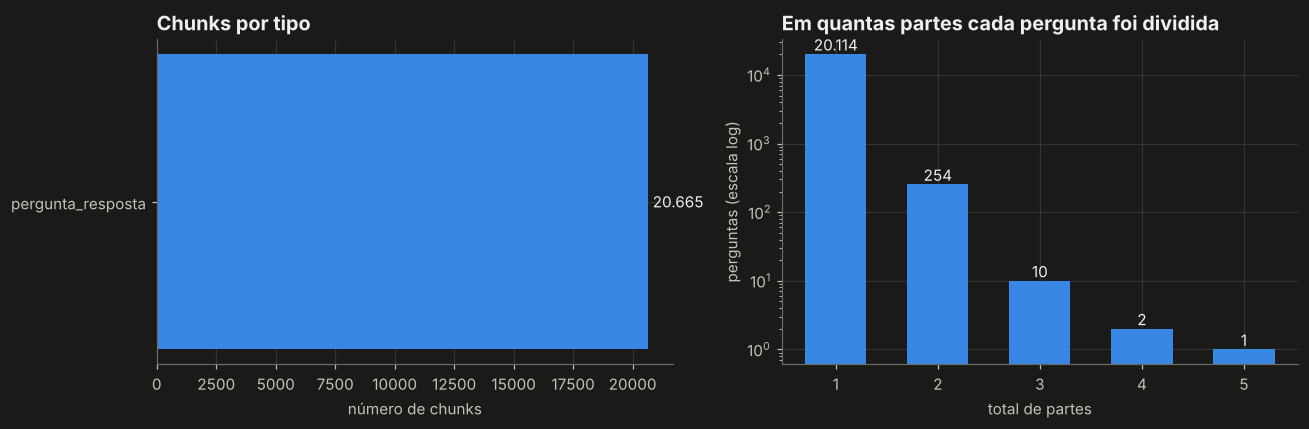

267 perguntas (1.3%) foram divididas em 2 ou mais chunks.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

tipos = df["tipo"].value_counts()
axes[0].barh(tipos.index, tipos.values, color=AZUL, height=0.5)
for i, v in enumerate(tipos.values):
    axes[0].text(v, i, f" {v:,}".replace(",", "."), va="center")
axes[0].set_title("Chunks por tipo")
axes[0].set_xlabel("número de chunks")

partes = pr.drop_duplicates("id_original")["total_partes"].value_counts().sort_index()
axes[1].bar(partes.index.astype(str), partes.values, color=AZUL, width=0.6)
axes[1].set_yscale("log")   # escala log: senão as barras pequenas somem
for x, v in zip(partes.index.astype(str), partes.values):
    axes[1].text(x, v, f"{v:,}".replace(",", "."), ha="center", va="bottom")
axes[1].set_title("Em quantas partes cada pergunta foi dividida")
axes[1].set_xlabel("total de partes")
axes[1].set_ylabel("perguntas (escala log)")
plt.tight_layout(); plt.show()

divididas = (pares["total_partes"] > 1).sum()
print(f"{divididas} perguntas ({divididas/len(pares):.1%}) foram divididas em 2 ou mais chunks.")

**Escala logarítmica:** cada marca do eixo vale 10 vezes a anterior. Sem ela, a barra de "1 parte"
(mais de 20 mil) esconderia as barras de 3, 4 e 5 partes (que têm só 1 a 10 perguntas).

Quais livros têm mais respostas divididas? Livros com respostas longas tendem a ter mais.

In [6]:
div_livro = (pares.assign(dividida=pares["total_partes"] > 1)
             .groupby("cultura")["dividida"].sum().sort_values(ascending=False))
div_livro[div_livro > 0].head(15).to_frame("perguntas divididas")

,perguntas divididas
cultura,
integracao-lavoura-pecuaria-floresta,60
suinos,23
sorgo,22
gado-de-leite,20
trigo,18
milho,14
pessego-nectarina-e-ameixa,10
soja,10
sementes,9


## 3. Os livros

### 3.1 Chunks por livro (cultura)
São 41 livros, cada um com 500 perguntas. Mas o número de **chunks** varia: sobe com as respostas
divididas em partes e desce com as perguntas que saíram no filtro (seção 10).

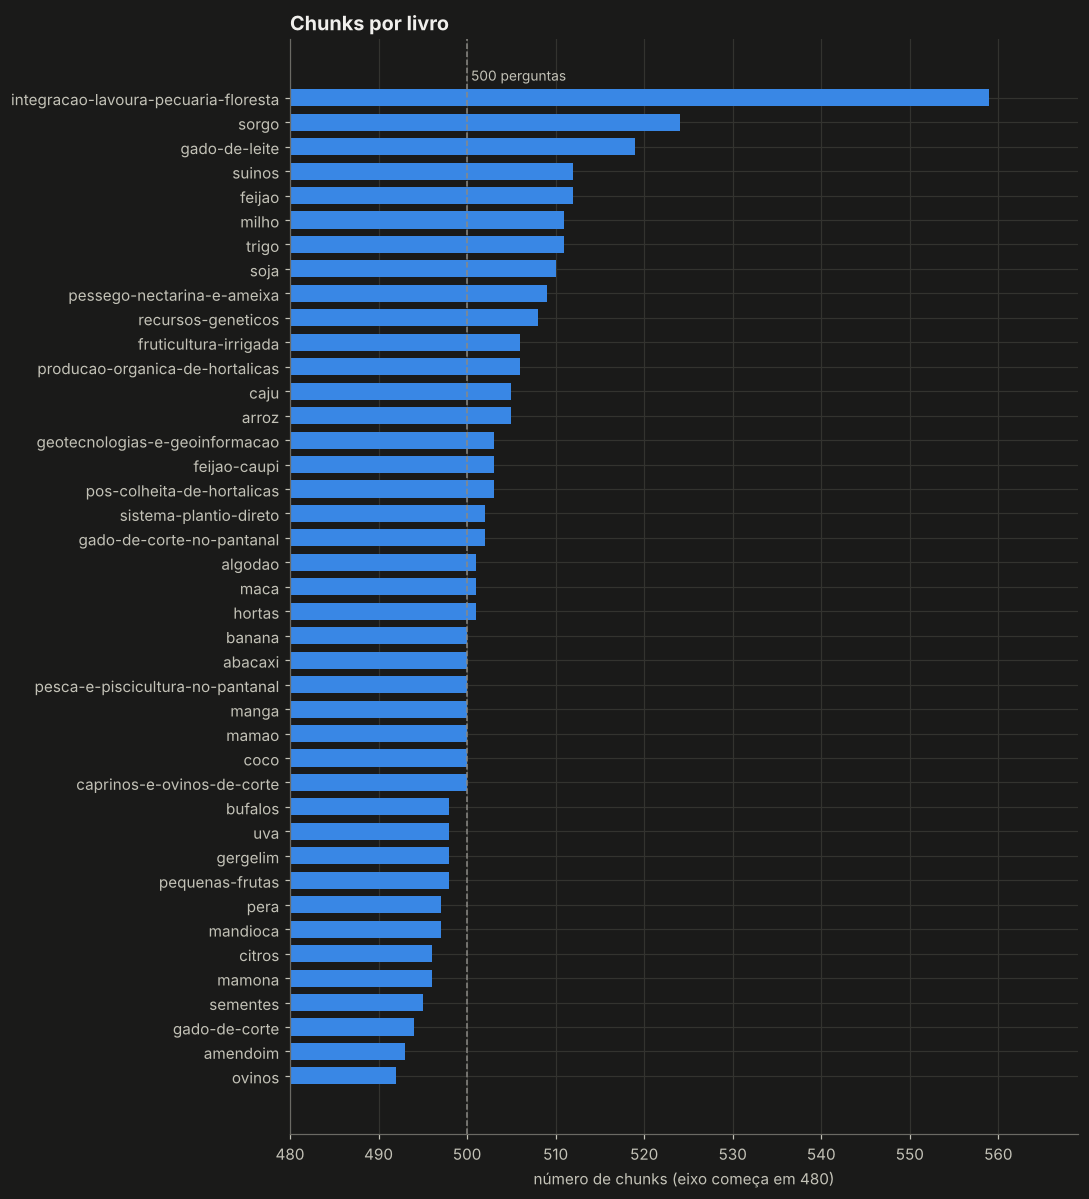

,count,mean,std,min,25%,50%,75%,max
chunks por livro,41.0,504.0,11.1,492.0,498.0,501.0,506.0,559.0


In [7]:
por_livro = df.groupby("cultura").size().sort_values()

fig, ax = plt.subplots(figsize=(10, 11))
ax.barh(por_livro.index, por_livro.values, color=AZUL, height=0.7)
ax.axvline(500, color=CINZA, linestyle="--", linewidth=1)
ax.text(500, len(por_livro) - 0.3, " 500 perguntas", color=TEXTO_2, fontsize=9)
ax.set_xlim(480, por_livro.max() + 10)   # começa em 480 para ver as diferenças
ax.set_title("Chunks por livro")
ax.set_xlabel("número de chunks (eixo começa em 480)")
plt.tight_layout(); plt.show()
por_livro.describe().round(1).to_frame("chunks por livro").T

**Atenção ao eixo:** ele começa em 480 de propósito, para mostrar as diferenças pequenas. Os livros
são quase do mesmo tamanho: o corpus é **equilibrado**, nenhuma cultura domina o índice. Isso é
bom para o RAG, porque a busca não fica "puxada" para um tema.

### 3.2 Ano de publicação, formato e edição

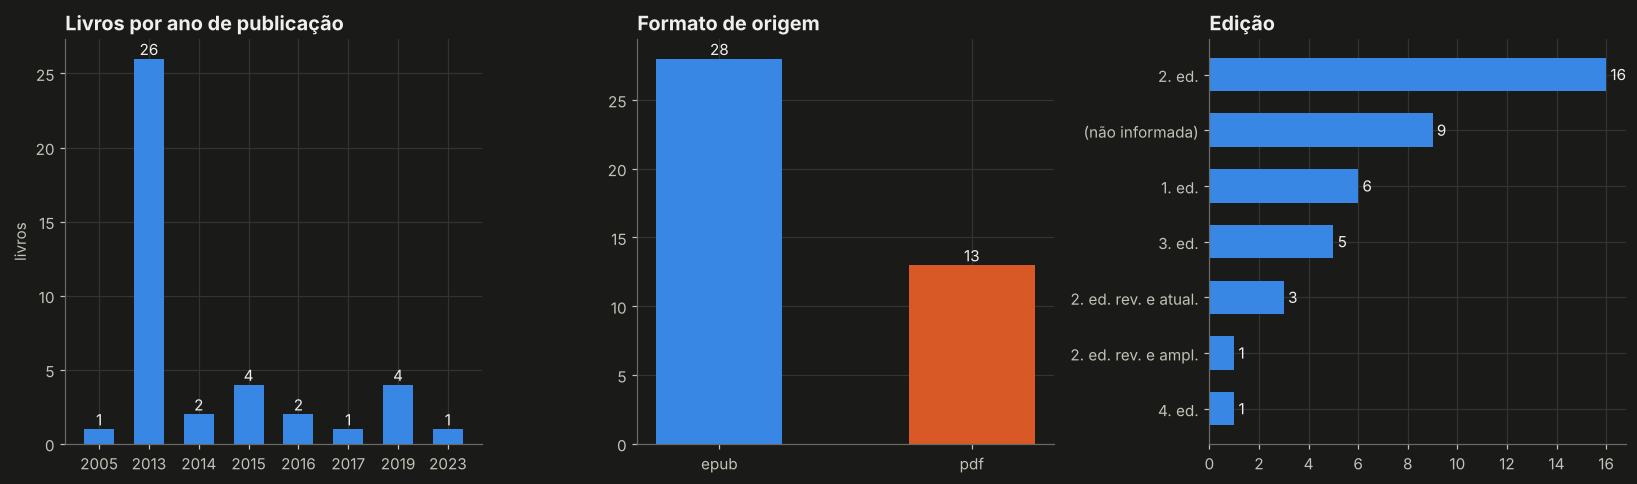

In [8]:
livros = df.drop_duplicates("cultura")[["cultura", "titulo_livro", "ano", "edicao", "formato_origem"]]
livros["edicao"] = livros["edicao"].replace("", "(não informada)")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

anos = livros["ano"].value_counts().sort_index()
axes[0].bar(anos.index.astype(str), anos.values, color=AZUL, width=0.6)
for x, v in zip(anos.index.astype(str), anos.values):
    axes[0].text(x, v, str(v), ha="center", va="bottom")
axes[0].set_title("Livros por ano de publicação")
axes[0].set_ylabel("livros")

fmt = livros["formato_origem"].value_counts()
axes[1].bar(fmt.index, fmt.values, color=[AZUL, LARANJA][:len(fmt)], width=0.5)
for x, v in zip(fmt.index, fmt.values):
    axes[1].text(x, v, str(v), ha="center", va="bottom")
axes[1].set_title("Formato de origem")

ed = livros["edicao"].value_counts().sort_values()
axes[2].barh(ed.index, ed.values, color=AZUL, height=0.6)
for i, v in enumerate(ed.values):
    axes[2].text(v, i, f" {v}", va="center")
axes[2].set_title("Edição")
plt.tight_layout(); plt.show()

Mais da metade dos livros é de **2013**. O mais antigo é de 2005 e o mais novo de 2023. Isso
importa porque **recomendações técnicas envelhecem** (produtos registrados, cultivares, legislação).
Vale guardar o ano junto do chunk para poder avisar o usuário ou filtrar.

A tabela abaixo lista todos os livros:

In [9]:
livros.sort_values(["ano", "cultura"]).reset_index(drop=True)

,cultura,titulo_livro,ano,edicao,formato_origem
0,caprinos-e-ovinos-de-corte,"Caprinos e ovinos de corte: o produtor pergunta, a Embrapa responde.",2005,1. ed.,pdf
1,abacaxi,"Abacaxi: o produtor pergunta, a Embrapa responde.",2013,2. ed. rev. e atual.,pdf
2,algodao,"Algodão: o produtor pergunta, a Embrapa responde.",2013,2. ed.,epub
3,amendoim,"Amendoim: o produtor pergunta, a Embrapa responde.",2013,2. ed.,epub
4,arroz,"Arroz: o produtor pergunta, a Embrapa responde.",2013,2. ed. rev. e ampl.,pdf
5,banana,"Banana: o produtor pergunta, a Embrapa responde.",2013,3. ed.,epub
6,bufalos,"Búfalos: o produtor pergunta, a Embrapa responde.",2013,2. ed.,epub
7,citros,"Citros: o produtor pergunta, a Embrapa responde.",2013,(não informada),epub
8,fruticultura-irrigada,"Fruticultura irrigada: o produtor pergunta, a Embrapa responde.",2013,2. ed.,epub
9,gado-de-corte,"Gado de corte: o produtor pergunta, a Embrapa responde.",2013,3. ed.,epub


## 4. Perguntas: estão todas lá?

Cada livro deveria ter as perguntas numeradas de 1 a 500. Vamos conferir se falta algum número ou
se algum número aparece repetido. Esse tipo de checagem pega erros da extração do texto.

Agora uma parte dos números falta **de propósito**: são as perguntas que o filtro tirou. Por isso a
checagem separa o que saiu no filtro (lido do corpus completo) do que realmente não foi extraído.

In [10]:
completo = pd.read_json(CAMINHO_COMPLETO, lines=True)
pares_completo = completo[completo["tipo"] == "pergunta_resposta"].drop_duplicates("id_original")
fora_filtro = set(pares_completo["id_original"]) - set(pares["id_original"])
num_fora = (pares_completo[pares_completo["id_original"].isin(fora_filtro)]
            .groupby("cultura")["numero_pergunta"].apply(lambda s: set(s.astype(int))))

linhas = []
for cultura, nums in pares.groupby("cultura")["numero_pergunta"]:
    nums = nums.astype(int)
    filtradas = num_fora.get(cultura, set())
    faltando = sorted(set(range(1, 501)) - set(nums) - filtradas)
    repetidos = sorted(nums[nums.duplicated()].unique())
    linhas.append({"cultura": cultura, "perguntas": len(nums), "fora_pelo_filtro": len(filtradas),
                   "faltando": faltando, "repetidos": repetidos})
checagem = pd.DataFrame(linhas)

problemas = checagem[(checagem["faltando"].str.len() > 0) | (checagem["repetidos"].str.len() > 0)]
print(f"Perguntas no corpus: {checagem['perguntas'].sum():,}; fora pelo filtro: {checagem['fora_pelo_filtro'].sum()}".replace(",", "."))
print(f"Livros sem falha de extração (1 a 500, contando as filtradas, sem repetição): {len(checagem) - len(problemas)} de {len(checagem)}")
problemas

Perguntas no corpus: 20.381; fora pelo filtro: 118
Livros sem falha de extração (1 a 500, contando as filtradas, sem repetição): 40 de 41


,cultura,perguntas,fora_pelo_filtro,faltando,repetidos
5,bufalos,496,3,[383],[]


Tirando as perguntas que saíram no filtro, só há um problema: **falta a pergunta 383 do livro de
búfalos**. Vale abrir o PDF/ePub original e ver se é um erro do livro (pulou o número) ou da nossa
extração.

## 5. Capítulos e temas

### 5.1 Quantos capítulos cada livro tem

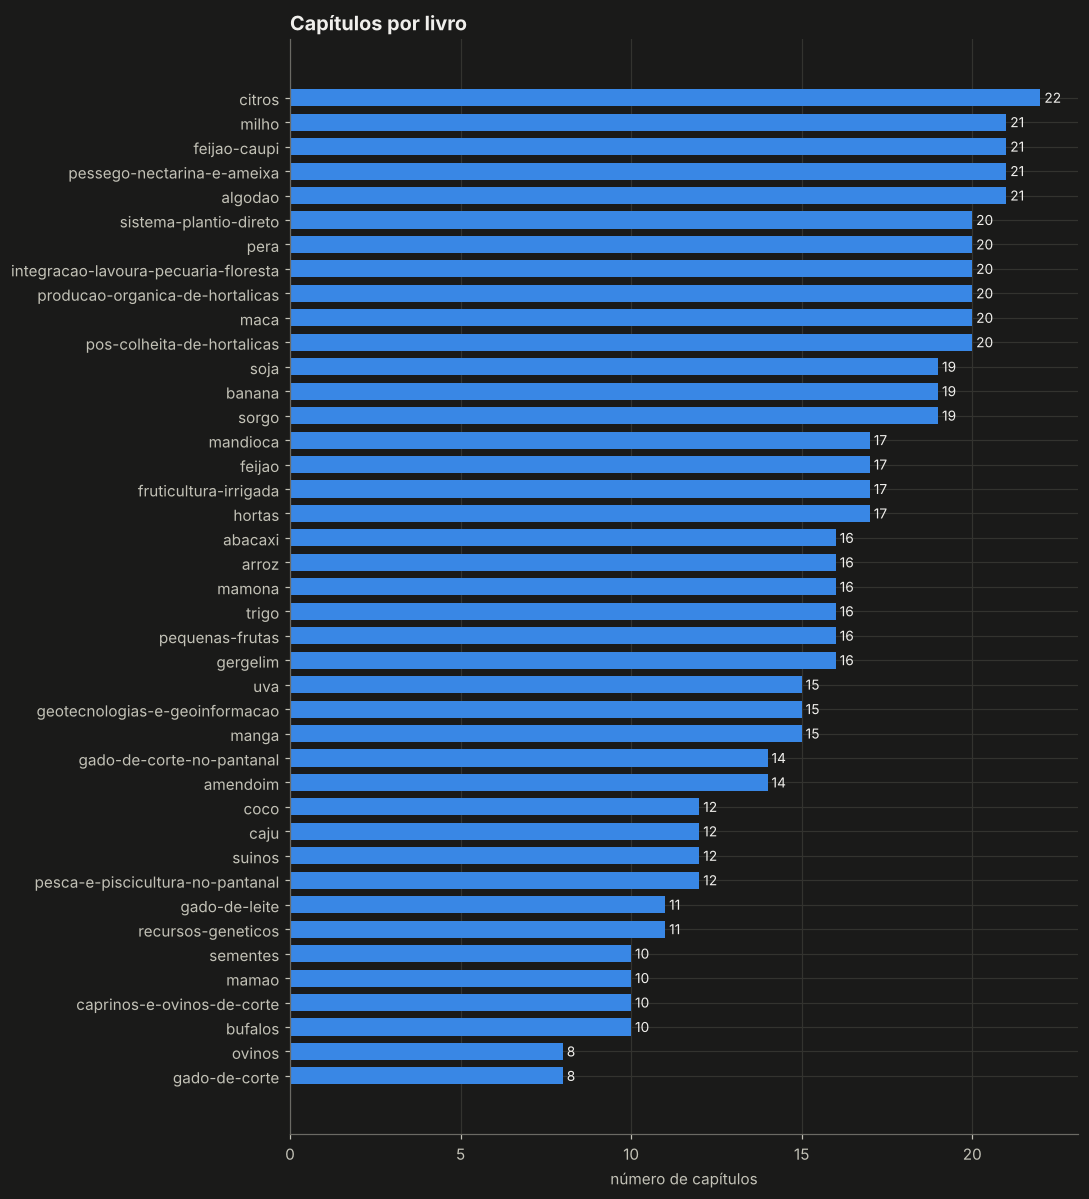

Média de 15.8 capítulos por livro; total de 458 nomes de capítulo diferentes.


In [11]:
caps = pares.groupby("cultura")["capitulo"].nunique().sort_values()

fig, ax = plt.subplots(figsize=(10, 11))
ax.barh(caps.index, caps.values, color=AZUL, height=0.7)
for i, v in enumerate(caps.values):
    ax.text(v, i, f" {v}", va="center", fontsize=9)
ax.set_title("Capítulos por livro")
ax.set_xlabel("número de capítulos")
plt.tight_layout(); plt.show()
print(f"Média de {caps.mean():.1f} capítulos por livro; total de {pares['capitulo'].nunique()} nomes de capítulo diferentes.")

### 5.2 Tamanho dos capítulos

Quantas perguntas tem um capítulo? O **histograma** mostra a distribuição: o eixo x é o número de
perguntas, e a altura da barra é quantos capítulos têm aquele tamanho.

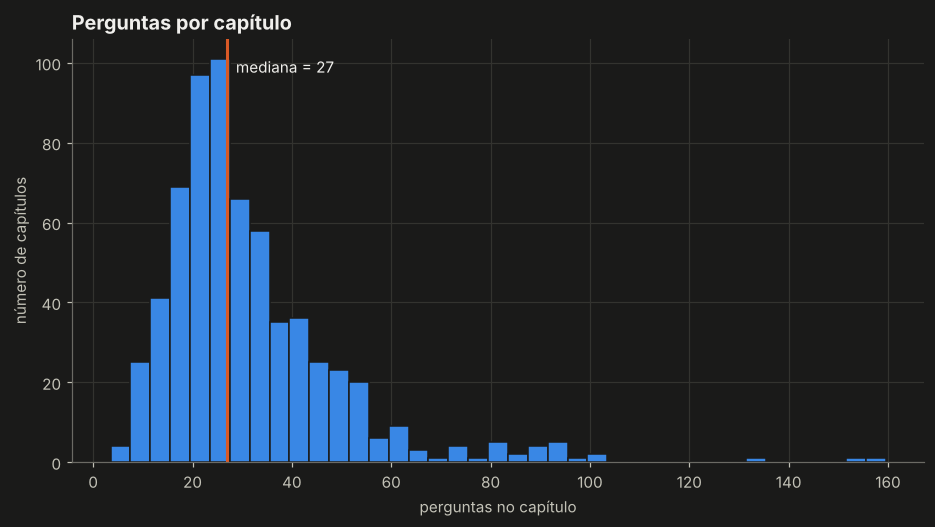

Maiores capítulos:


,,perguntas
cultura,capitulo,
ovinos,Saúde Ovina,159
gado-de-leite,Recursos Forrageiros,154
gado-de-corte,Pastagem,134
fruticultura-irrigada,Manejo da Cultura da Manga,102
caju,Aproveitamento Industrial,102
bufalos,Eficiência Reprodutiva,98
suinos,Sanidade,95
bufalos,Alimentação,94


Menores capítulos:


,,perguntas
cultura,capitulo,
suinos,Secagem e Armazenagem,4
citros,Cultivares,4
manga,Classificação e Descrição Botânica,5
citros,Economia,7
feijao,Produção de Sementes e Comercialização,8
sistema-plantio-direto,Agricultura de Precisão,8
gado-de-leite,Produção Orgânica de Leite,8
citros,Classificação Botânica,8


In [12]:
tam_cap = pares.groupby(["cultura", "capitulo"]).size()

fig, ax = plt.subplots()
ax.hist(tam_cap, bins=faixas_inteiras(tam_cap, 40), color=AZUL, edgecolor=FUNDO)
ax.axvline(tam_cap.median(), color=LARANJA, linewidth=2)
ax.text(tam_cap.median(), ax.get_ylim()[1] * 0.92, f"  mediana = {tam_cap.median():.0f}", color=TEXTO)
ax.set_title("Perguntas por capítulo")
ax.set_xlabel("perguntas no capítulo")
ax.set_ylabel("número de capítulos")
plt.show()

print("Maiores capítulos:")
display(tam_cap.sort_values(ascending=False).head(8).to_frame("perguntas"))
print("Menores capítulos:")
display(tam_cap.sort_values().head(8).to_frame("perguntas"))

**Mediana** é o valor do meio: metade dos capítulos tem menos perguntas que ela, metade tem mais.
Ela é mais robusta que a média quando existem valores extremos.

### 5.3 Temas que se repetem entre livros

Muitos livros têm capítulos com o mesmo assunto (pragas, doenças, irrigação...). Para comparar,
normalizamos o nome (minúsculas e sem acento) e contamos em quantos livros cada tema aparece.

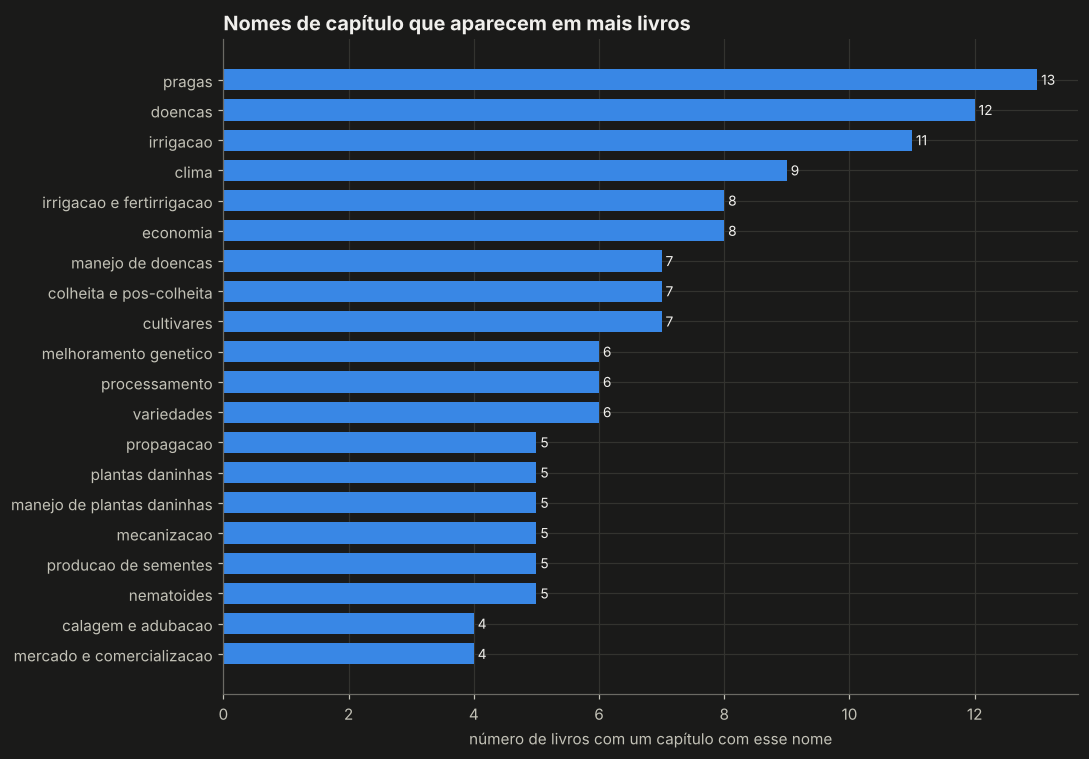

In [13]:
import unicodedata

def normalizar(s):
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s.lower()).strip()

pares = pares.assign(capitulo_norm=pares["capitulo"].map(normalizar))
temas = (pares.groupby("capitulo_norm")
         .agg(livros=("cultura", "nunique"), perguntas=("id_original", "size"))
         .sort_values(["livros", "perguntas"], ascending=False))

top = temas.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top.index, top["livros"], color=AZUL, height=0.7)
for i, v in enumerate(top["livros"]):
    ax.text(v, i, f" {v}", va="center", fontsize=9)
ax.set_title("Nomes de capítulo que aparecem em mais livros")
ax.set_xlabel("número de livros com um capítulo com esse nome")
plt.tight_layout(); plt.show()

Os nomes exatos variam muito ("Doenças", "Manejo de Doenças", "Doenças e seu Controle"...).
Uma forma mais robusta é procurar **palavras-chave** no nome do capítulo e agrupar em grandes
temas. Abaixo, uma classificação simples feita à mão:

Capítulos que ficaram em Outros: 13 (369 perguntas)


,,perguntas
cultura,capitulo,
sementes,"Conceitos, Definições e Abordagens Gerais",93
pequenas-frutas,Generalidades,39
hortas,Hortaliças,30
algodao,Algodão Colorido no Brasil e no Mundo,29
hortas,Hortas,29
pos-colheita-de-hortalicas,Produção e Consumo de Hortaliças,25
hortas,Escolhas das Hortaliças,21
producao-organica-de-hortalicas,Princípios Norteadores,21
pera,Generalidades,21


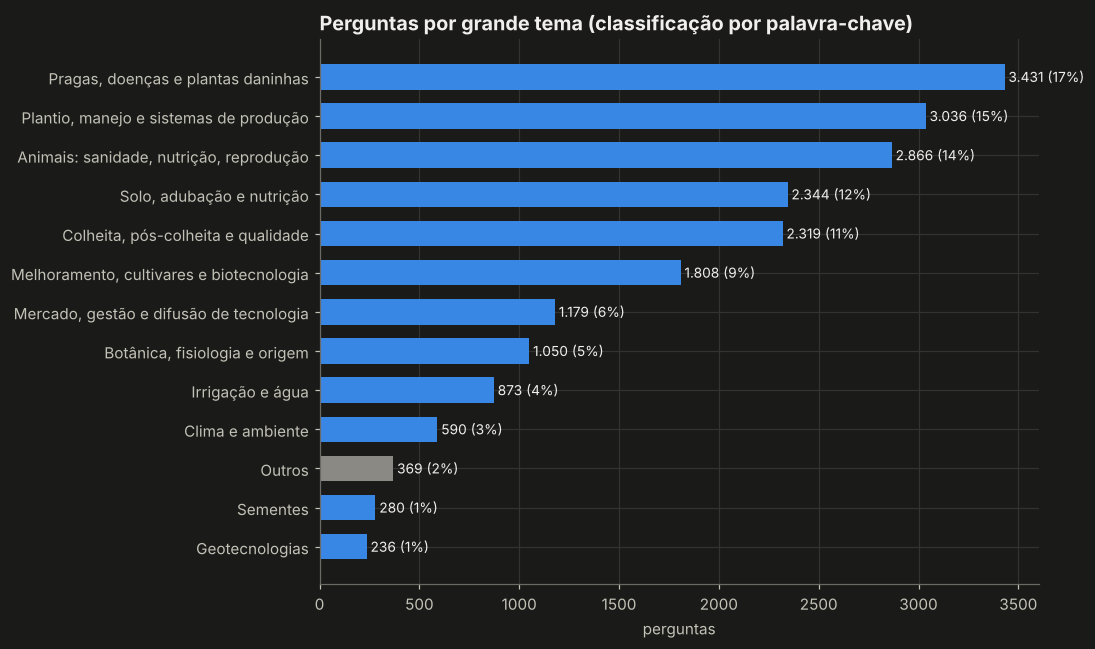

In [14]:
# Cada palavra-chave precisa aparecer no COMEÇO de uma palavra do nome do capítulo
# (por isso "fisiolog" não pega "ecofisiologia", e essa entra separada).
# A ORDEM IMPORTA: o capítulo fica no primeiro tema cuja palavra-chave aparecer no nome.
# Por isso os temas mais específicos vêm antes (ex.: "manejo de doenças" tem que cair em
# pragas e doenças, e não em manejo da cultura).
# As palavras estão sem acento e em minúsculas, como o nome normalizado.
GRANDES_TEMAS = {
    "Pragas, doenças e plantas daninhas": [
        "praga", "doenc", "fitossan", "nematoide", "inseto", "daninha", "invasora", "espontanea",
        "infestante", "virus", "virose", "controle biologico", "agrotox", "defensivo",
        "morte precoce", "solarizacao"],
    "Irrigação e água": ["irriga", "agua", "hidric", "quimigacao", "hidrolog"],
    "Solo, adubação e nutrição": [
        "solo", "aduba", "nutri", "fertili", "calag", "fertirriga", "compostagem", "palha", "material organico",
        "fixacao biologica", "terraco"],
    "Colheita, pós-colheita e qualidade": [
        "colheita", "armazen", "beneficia", "processa", "industria", "subproduto", "oleo",
        "fibra", "fiacao", "qualidade", "embalage", "logistica", "resfriamento", "injuria",
        "desordens", "conservar", "silagem", "biodiesel", "quimica do", "bioquimica", "secagem",
        "agroindustria", "alimentacao humana", "na alimentacao", "seguranca alimentar", "beneficios"],
    "Melhoramento, cultivares e biotecnologia": [
        "melhora", "cultivar", "genetic", "variedade", "biotecnolog", "biologia molecular",
        "transgenico", "milhos especiais"],
    "Sementes": ["semente"],
    "Botânica, fisiologia e origem": [
        "botanic", "fisiolog", "florescimento", "frutificacao", "dormencia", "germinacao",
        "origem", "historia", "curiosidade", "estrutura da planta", "estruturas da planta",
        "reguladores de crescimento", "ecofisiolog", "floracao", "taxonomia", "citogenetica", "respiracao", "transpiracao"],
    "Plantio, manejo e sistemas de produção": [
        "plantio", "propaga", "semeadura", "muda", "implanta", "manejo da cultura",
        "manejo cultural", "manejo do pomar", "manejo da soca", "pratica", "trato", "poda",
        "raleio", "conducao", "instalacao do", "instalacao de", "instalacao dos", "consorci",
        "consorcio", "rotac", "sucess", "sistemas de cultivo", "mecanizacao", "maniva",
        "safrinha", "substituicao de copas", "planejamento", "insumos", "producao integrada",
        "producao organica", "organica", "agricultura de precisao", "bioenergia", "copa",
        "integracao", "micropropaga", "microenxert"],
    "Animais: sanidade, nutrição, reprodução": [
        "sanidade", "saude ovina", "reproduc", "reprodutiva", "alimentacao animal", "alimentos alternativos",
        "pastag", "forrage", "rebanho", "raca", "cria", "abate", "carne", "leite", "peixe",
        "piscicult", "pesca", "vacas", "touros", "cavalo", "trabalho animal", "bem-estar",
        "zootecnica", "ambiencia", "dejetos", "caprinos", "ovinos"],
    "Clima e ambiente": [
        "clima", "ambient", "zonea", "agrometeorolog", "co2", "ecossistema", "contaminacao",
        "exotica"],
    "Mercado, gestão e difusão de tecnologia": [
        "mercado", "economi", "comercial", "custo", "gestao", "socioecon", "transferencia",
        "extensao", "assistencia tecnica", "organizacao", "adocao", "legislacao", "certificacao",
        "fontes de informacao", "perspectivas", "panorama", "tendencias", "educacao",
        "experimentacao", "estatistica"],
}

# Livros inteiros sobre animais ou sobre geotecnologia: um capítulo genérico deles
# (ex.: "Manejo" no livro de suínos) pertence ao tema do livro.
LIVROS_ANIMAIS = {"bufalos", "caprinos-e-ovinos-de-corte", "gado-de-corte", "gado-de-corte-no-pantanal",
                  "gado-de-leite", "ovinos", "suinos", "pesca-e-piscicultura-no-pantanal"}

def grande_tema(nome, cultura):
    for tema, chaves in GRANDES_TEMAS.items():
        # \b = "começo de palavra". Sem ele, "raca" (raça) casaria com "floRAÇÃo" e "integRAÇÃo"!
        if any(re.search(r"\b" + re.escape(k), nome) for k in chaves):
            return tema
    if cultura in LIVROS_ANIMAIS:
        return "Animais: sanidade, nutrição, reprodução"
    if cultura == "geotecnologias-e-geoinformacao":
        return "Geotecnologias"
    return "Outros"

pares = pares.assign(grande_tema=[grande_tema(n, c) for n, c in zip(pares["capitulo_norm"], pares["cultura"])])

# Para conferir: quais capítulos ainda ficaram sem tema?
sem_tema = (pares[pares["grande_tema"] == "Outros"].groupby(["cultura", "capitulo"]).size()
            .sort_values(ascending=False))
print(f"Capítulos que ficaram em Outros: {len(sem_tema)} ({sem_tema.sum()} perguntas)")
display(sem_tema.to_frame("perguntas"))
gt = pares["grande_tema"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
cores = [CINZA if t == "Outros" else AZUL for t in gt.index]
ax.barh(gt.index, gt.values, color=cores, height=0.65)
for i, v in enumerate(gt.values):
    ax.text(v, i, f" {v:,} ({v/len(pares):.0%})".replace(",", "."), va="center", fontsize=9)
ax.set_title("Perguntas por grande tema (classificação por palavra-chave)")
ax.set_xlabel("perguntas")
plt.tight_layout(); plt.show()

Como montar uma classificação dessas: na primeira versão, quase um terço das perguntas caiu em
**Outros**. A solução foi listar os capítulos que sobraram (a tabela acima faz isso), ler os
nomes e acrescentar palavras-chave até "Outros" ficar pequeno. É um processo iterativo, e vale
repetir sempre que os dados mudarem.

Ainda é uma classificação aproximada: um capítulo como "Doenças e irrigação" cai só no primeiro
tema que bater. Mesmo assim, mostra o perfil do corpus. Isso ajuda a montar o *golden set*: as
perguntas de teste deveriam seguir mais ou menos essa proporção.

Um mapa de calor (*heatmap*) mostra o mesmo por livro: cada célula é a fração das perguntas daquele
livro em cada tema. Quanto mais escura, maior a fração.

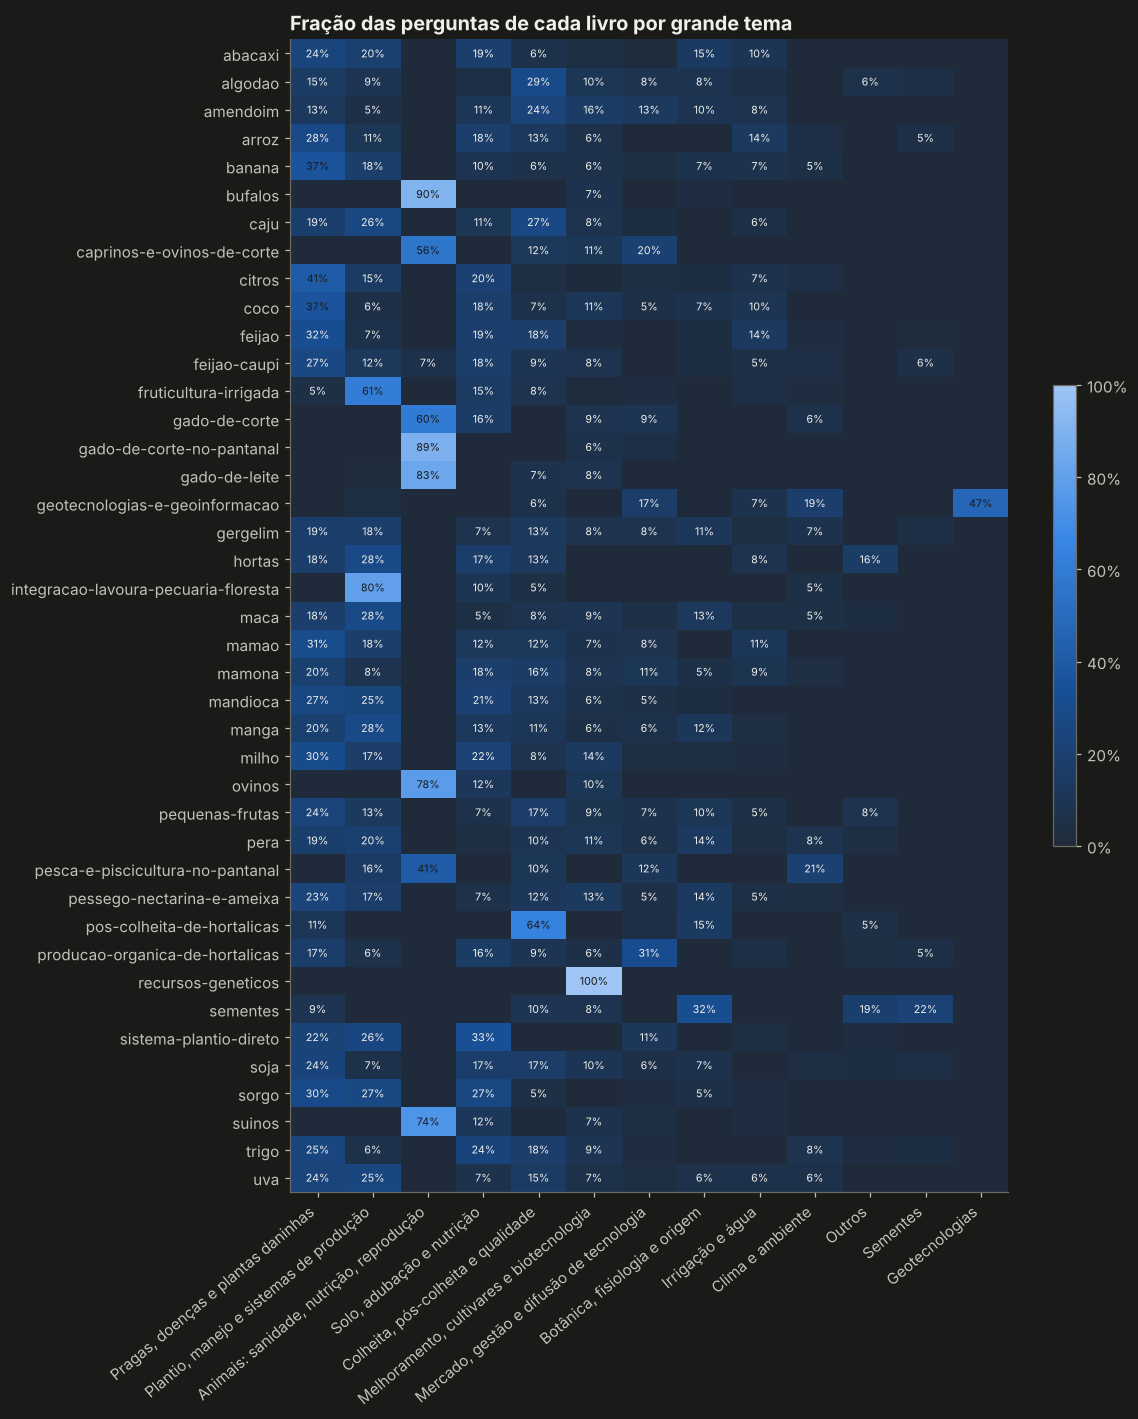

In [15]:
from matplotlib.colors import LinearSegmentedColormap

tab = pd.crosstab(pares["cultura"], pares["grande_tema"], normalize="index")
tab = tab[gt.index[::-1]]   # mesma ordem do gráfico anterior
azuis = LinearSegmentedColormap.from_list("azuis", ESCALA)

fig, ax = plt.subplots(figsize=(11, 13))
im = ax.imshow(tab.values, cmap=azuis, aspect="auto", vmin=0)
ax.set_xticks(range(tab.shape[1]), tab.columns, rotation=40, ha="right")
ax.set_yticks(range(tab.shape[0]), tab.index)
ax.grid(False)
for i in range(tab.shape[0]):
    for j in range(tab.shape[1]):
        v = tab.values[i, j]
        if v >= 0.05:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7,
                    color=(FUNDO if TEMA_ESCURO else "white") if v > 0.35 else TEXTO)
ax.set_title("Fração das perguntas de cada livro por grande tema")
fig.colorbar(im, ax=ax, shrink=0.4, format=lambda x, _: f"{x:.0%}")
plt.tight_layout(); plt.show()

## 6. Tamanho dos textos

Esta é a parte mais importante para o RAG:
- O modelo de embedding (`multilingual-e5-small`) tem limite de **512 tokens**. O que passar disso é
  cortado e não entra no vetor.
- Textos muito curtos podem ter pouca informação; textos muito longos misturam assuntos.

### 6.1 Resumo estatístico

`describe()` dá contagem, média, desvio padrão (*std*, o quanto os valores se espalham), mínimo,
quartis (25%, 50% = mediana, 75%) e máximo.

In [16]:
cols = ["pergunta_palavras", "resposta_palavras", "texto_palavras", "texto_chars"]
pr[cols].describe().round(1)

,pergunta_palavras,resposta_palavras,texto_palavras,texto_chars
count,20665.0,20665.0,20665.0,20665.0
mean,11.4,82.1,100.9,656.6
std,4.6,57.6,59.0,376.5
min,2.0,1.0,10.0,66.0
25%,8.0,41.0,59.0,384.0
50%,11.0,67.0,86.0,560.0
75%,14.0,107.0,126.0,823.0
max,45.0,352.0,374.0,2372.0


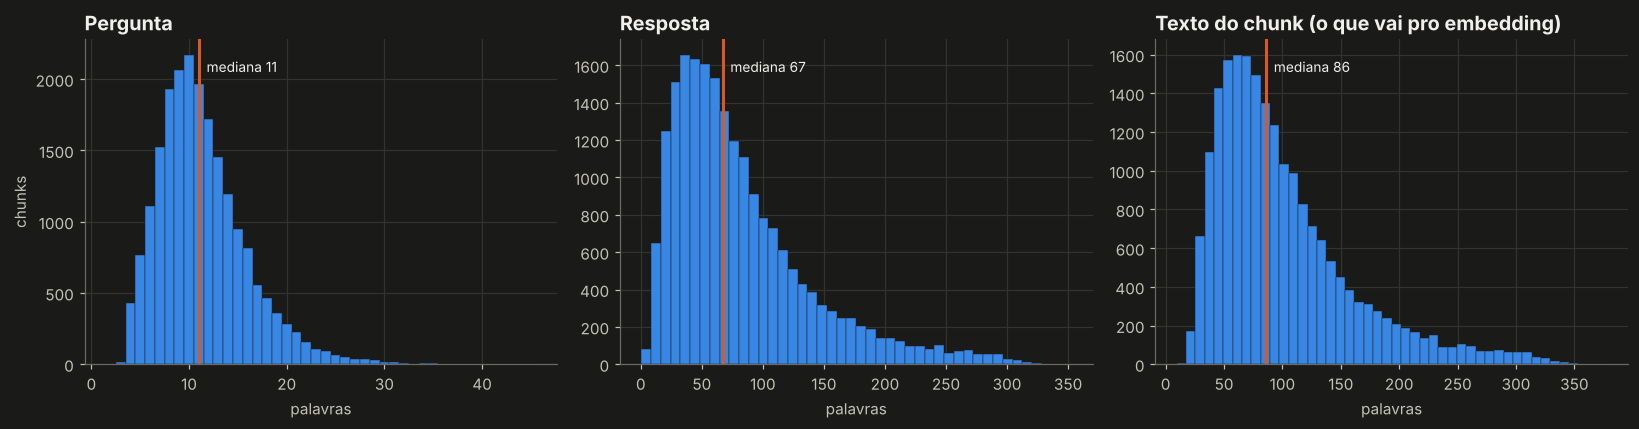

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, titulo in zip(axes,
                           ["pergunta_palavras", "resposta_palavras", "texto_palavras"],
                           ["Pergunta", "Resposta", "Texto do chunk (o que vai pro embedding)"]):
    dados = pr[col]
    ax.hist(dados, bins=faixas_inteiras(dados),  # faixas de largura inteira: sem buracos falsos
            color=AZUL, edgecolor=FUNDO, linewidth=0.3)
    ax.axvline(dados.median(), color=LARANJA, linewidth=2)
    ax.text(dados.median(), ax.get_ylim()[1] * 0.9, f"  mediana {dados.median():.0f}", fontsize=9)
    ax.set_title(titulo)
    ax.set_xlabel("palavras")
axes[0].set_ylabel("chunks")
plt.tight_layout(); plt.show()

As distribuições são **assimétricas à direita** (cauda longa): a maioria dos textos é curta, mas
existem alguns bem longos. É o padrão comum em texto. As perguntas são curtas (mediana de 11 palavras), o que é parecido com o jeito que um produtor faria uma pergunta ao sistema.

**Por que as faixas têm largura inteira?** Na primeira versão deste gráfico, o histograma das
perguntas tinha barras faltando. Não era falta de dados: as perguntas têm de 2 a 45 palavras, e
`bins=50` dividia esse intervalo em 50 faixas de 0,86 palavra cada. Como ninguém escreve uma
pergunta com 8,5 palavras, algumas faixas caíam entre dois inteiros e ficavam vazias. A função
`faixas_inteiras` (definida na célula de preparação) resolve isso: cada faixa tem largura inteira
(1 palavra nas perguntas, várias nas respostas) e as bordas ficam no meio entre dois inteiros.

### 6.2 Tokens e o limite de 512

Um **token** é o pedaço de texto que o modelo enxerga (pode ser uma palavra inteira ou um pedaço
dela). O modelo e5 também exige o prefixo `passage: ` antes de cada texto indexado. A célula abaixo
tenta usar o tokenizador real; se não conseguir, estima tokens como `palavras × 1,6` (em português,
o tokenizador do e5 gera em média entre 1,4 e 1,8 tokens por palavra).

In [18]:
try:
    from tokenizers import Tokenizer
    tok = Tokenizer.from_pretrained("intfloat/multilingual-e5-small")
    encs = tok.encode_batch(("passage: " + pr["texto"]).tolist())
    pr = pr.assign(tokens=[len(e.ids) for e in encs])
    FONTE_TOKENS = "tokenizador real do multilingual-e5-small"
except Exception as erro:
    pr = pr.assign(tokens=(pr["texto_palavras"] * 1.6).round().astype(int))
    FONTE_TOKENS = "estimativa (palavras x 1,6)"
    print("Tokenizador indisponível, usando estimativa:", type(erro).__name__)

print("Fonte da contagem:", FONTE_TOKENS)
pr["tokens"].describe().round(1).to_frame("tokens por chunk").T

Fonte da contagem: tokenizador real do multilingual-e5-small


,count,mean,std,min,25%,50%,75%,max
tokens por chunk,20665.0,171.3,94.0,28.0,104.0,147.0,211.0,512.0


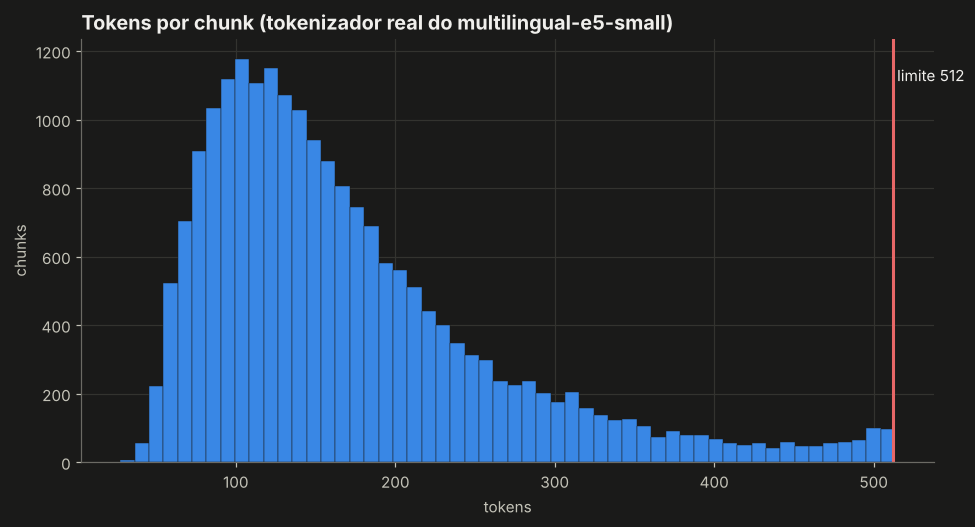

chunks com até 128 tokens: 40.0%
chunks com até 256 tokens: 84.4%
chunks com até 384 tokens: 95.7%
chunks com até 512 tokens: 100.0%
chunks acima de 512 segundo esta contagem: 0


In [19]:
fig, ax = plt.subplots()
ax.hist(pr["tokens"], bins=faixas_inteiras(pr["tokens"], 60), color=AZUL, edgecolor=FUNDO, linewidth=0.3)
ax.axvline(512, color=VERMELHO, linewidth=2)
ax.text(512, ax.get_ylim()[1] * 0.9, " limite 512", color=TEXTO)
ax.set_title(f"Tokens por chunk ({FONTE_TOKENS})")
ax.set_xlabel("tokens")
ax.set_ylabel("chunks")
plt.show()

for limite in [128, 256, 384, 512]:
    print(f"chunks com até {limite} tokens: {(pr['tokens'] <= limite).mean():.1%}")
print(f"chunks acima de 512 segundo esta contagem: {(pr['tokens'] > 512).sum()}")

Se a contagem for a real, nenhum chunk deve passar de 512, porque a divisão foi feita justamente
com esse limite. Se for a estimativa, alguns aparecem acima de 512: é erro da estimativa (a razão
tokens/palavra muda de texto para texto), não dos dados. O que importa aqui é o formato geral: quase
todos os chunks usam bem menos da metade da janela de 512 tokens.

### 6.3 Tamanho das respostas por livro

O **boxplot** (diagrama de caixa) resume uma distribuição: a caixa vai do 1º ao 3º quartil (50% do
meio dos dados), a linha dentro dela é a mediana, e as "hastes" mostram até onde vão os valores
típicos. Pontos fora das hastes (*outliers*) foram escondidos para o gráfico ficar legível.

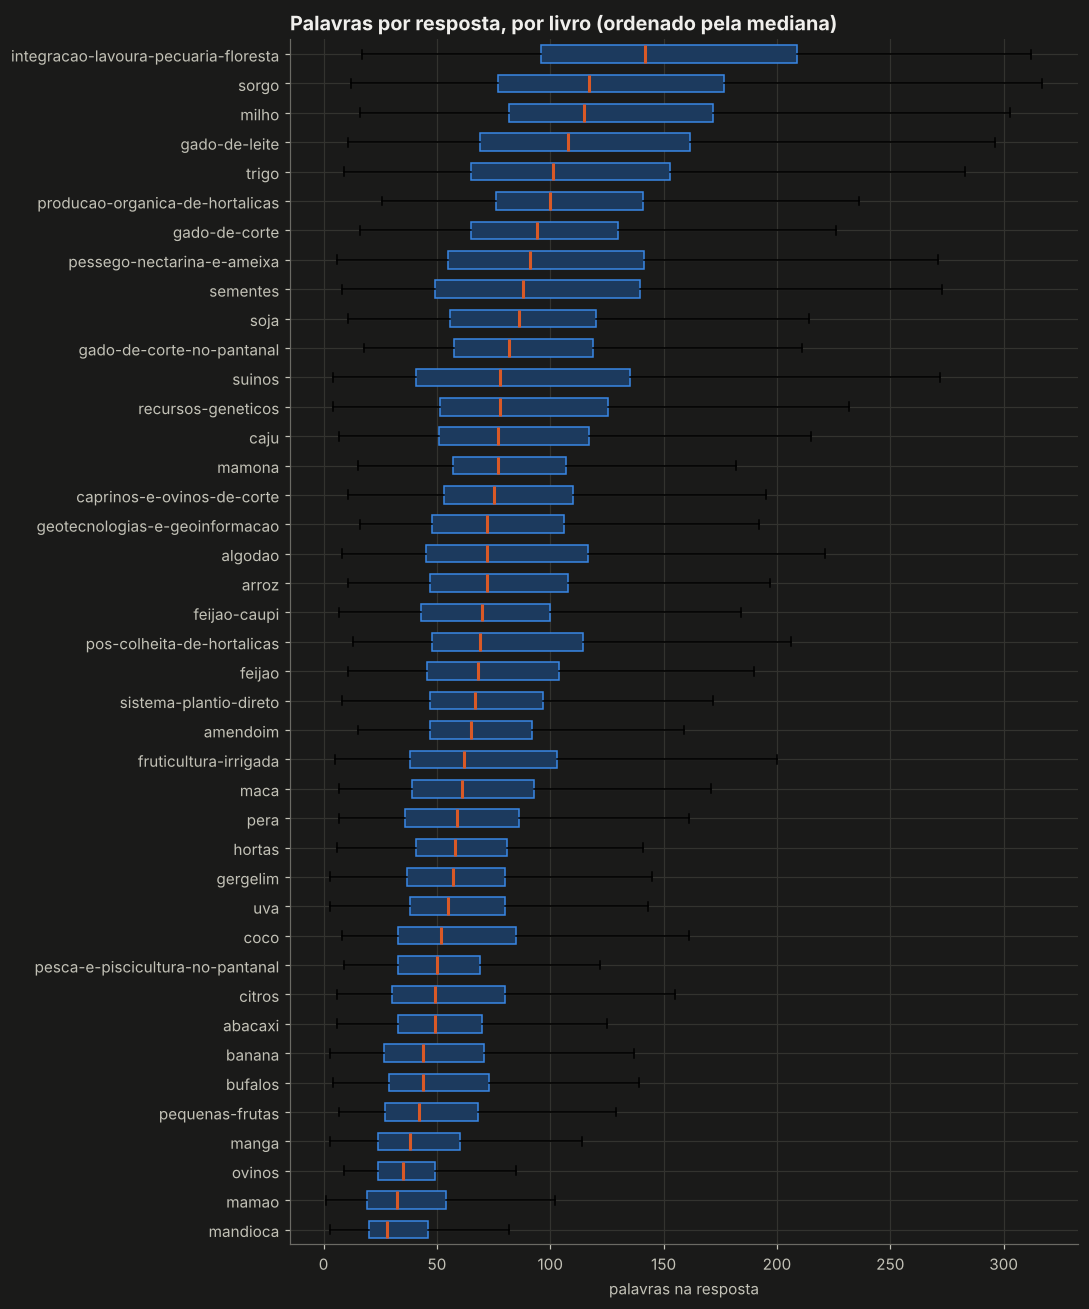

In [20]:
ordem = pares.groupby("cultura")["resposta_palavras"].median().sort_values().index
dados = [pares.loc[pares["cultura"] == c, "resposta_palavras"] for c in ordem]

fig, ax = plt.subplots(figsize=(10, 12))
bp = ax.boxplot(dados, vert=False, showfliers=False, patch_artist=True, widths=0.6,
                medianprops=dict(color=LARANJA, linewidth=2))
for caixa in bp["boxes"]:
    caixa.set(facecolor=AZUL_CLARO, edgecolor=AZUL)
ax.set_yticks(range(1, len(ordem) + 1), ordem)
ax.set_title("Palavras por resposta, por livro (ordenado pela mediana)")
ax.set_xlabel("palavras na resposta")
plt.tight_layout(); plt.show()

Alguns livros têm respostas bem mais longas que outros. Livros com respostas curtas produzem
chunks "diretos", enquanto os de respostas longas tendem a ter mais chunks divididos.

### 6.4 Os extremos

Olhar os menores e maiores textos ajuda a achar problemas (resposta truncada, lixo de extração).

In [21]:
print("RESPOSTAS MAIS CURTAS")
display(pares.nsmallest(8, "resposta_palavras")[["id", "pergunta", "resposta"]])
print("RESPOSTAS MAIS LONGAS (palavras somando todas as partes)")
total_resp = pr.groupby("id_original")["resposta_palavras"].sum().sort_values(ascending=False)
display(total_resp.head(8).to_frame("palavras na resposta completa"))

RESPOSTAS MAIS CURTAS


,id,pergunta,resposta
10943,mamao_2013_q348,O ácaro-branco tece teias?,Não.
2489,banana_2013_q491,Qual o maior importador mundial de banana?,Os Estados Unidos.
8794,gergelim_2013_q260,Que sistema de distribuição de sementes pequenas seria mais recomendado para produtores que desejam investir em alta...,O sistema pneumático.
11877,mandioca_2013_q287,"É possível fazer o Sistema Plantio Direto (SPD), na cultura da mandioca?","Sim, é possível."
12574,manga_2013_q486,Qual o principal ponto de venda de manga na Europa e nos Estados Unidos?,São os supermercados.
20654,uva_2013_q490,Quais são os principais países exportadores de uva de mesa?,Chile e Itália.
2603,bufalos_2013_q104,A mistura mineral feita para bovinos serve para bubalinos?,"De modo geral, sim."
2664,bufalos_2013_q165,O leite das búfalas com mamite pode ser aproveitado?,Não. Em hipótese nenhuma.


RESPOSTAS MAIS LONGAS (palavras somando todas as partes)


,palavras na resposta completa
id_original,
sorgo_2015_q159,1240
feijao_2015_q146,994
fruticultura-irrigada_2013_q313,806
gado-de-leite_2013_q353,749
feijao_2015_q321,697
integracao-lavoura-pecuaria-floresta_2015_q055,653
gado-de-leite_2013_q081,610
feijao-caupi_2017_q099,599


Respostas muito curtas como "Sim." ou "Não." são normais nesse tipo de livro, mas sozinhas
dependem muito da pergunta. Como o `texto` sempre inclui a pergunta, o chunk ainda faz sentido.

### 6.5 Existe relação entre o tamanho da pergunta e o da resposta?

O **gráfico de dispersão** coloca cada pergunta como um ponto. Se os pontos formassem uma diagonal,
perguntas longas teriam respostas longas. A **correlação** resume isso num número de -1 a 1
(0 = nenhuma relação linear).

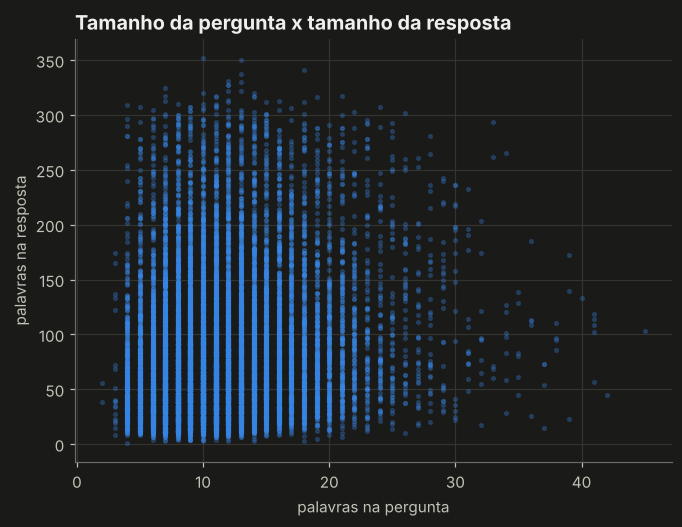

Correlação de Spearman: 0.15


In [22]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(pares["pergunta_palavras"], pares["resposta_palavras"], s=6, alpha=0.25, color=AZUL)
ax.set_title("Tamanho da pergunta x tamanho da resposta")
ax.set_xlabel("palavras na pergunta")
ax.set_ylabel("palavras na resposta")
plt.show()

# Spearman = correlação comum (Pearson) calculada sobre as posições (ranks) dos valores
corr = pares["pergunta_palavras"].rank().corr(pares["resposta_palavras"].rank())
print(f"Correlação de Spearman: {corr:.2f}")

O valor fica perto de 0,15: uma relação **fraca**. O tamanho da pergunta quase não diz nada
sobre o tamanho da resposta.

Usamos a correlação de **Spearman**, que olha a ordem dos valores em vez dos valores em si. Ela é
mais adequada quando a distribuição tem cauda longa, como aqui.

## 7. Como as perguntas são feitas

As perguntas dos livros são o melhor exemplo que temos de como um produtor pergunta. Ver as
palavras iniciais mostra os tipos de pergunta (definição, procedimento, causa...).

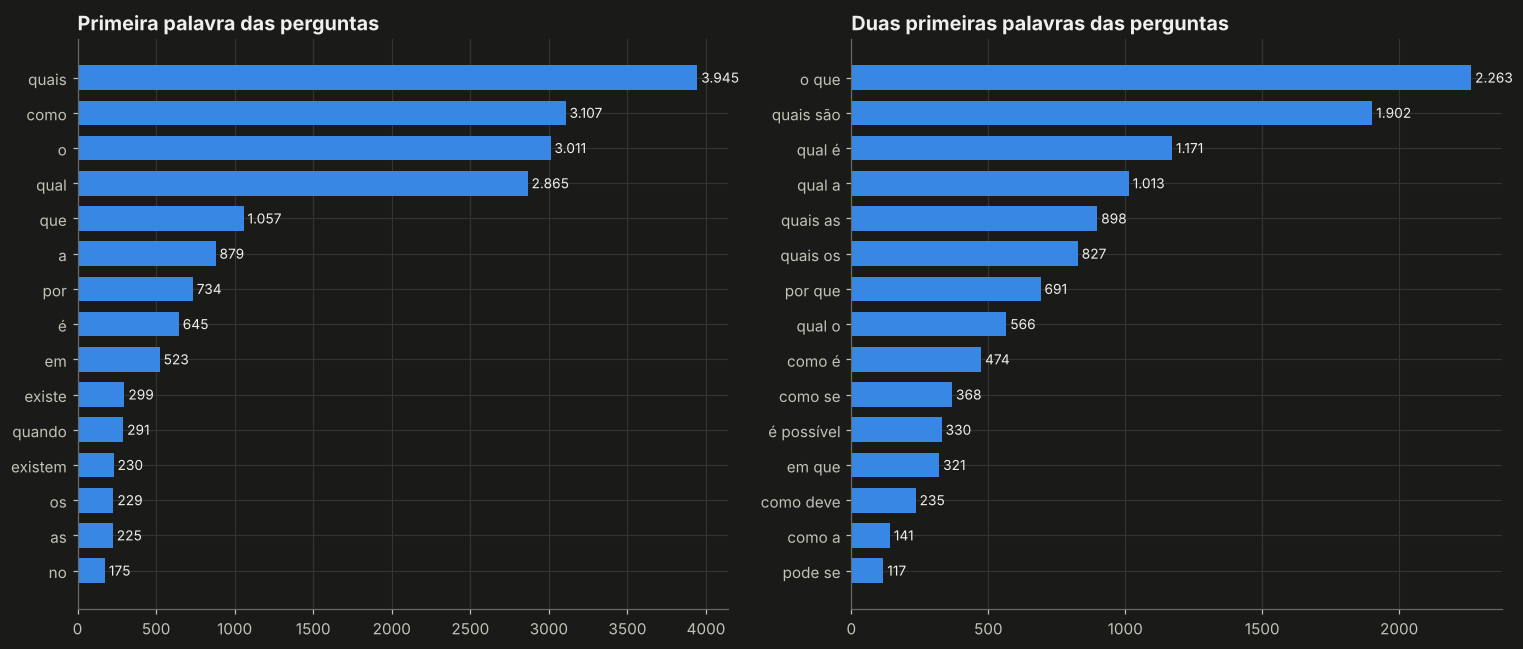

In [23]:
def inicio(p, n=2):
    palavras = re.findall(r"\w+", p.lower())
    return " ".join(palavras[:n])

pares = pares.assign(primeira=pares["pergunta"].map(lambda p: inicio(p, 1)),
                     duas_primeiras=pares["pergunta"].map(lambda p: inicio(p, 2)))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, col, titulo in zip(axes, ["primeira", "duas_primeiras"],
                           ["Primeira palavra", "Duas primeiras palavras"]):
    top = pares[col].value_counts().head(15).iloc[::-1]
    ax.barh(top.index, top.values, color=AZUL, height=0.7)
    for i, v in enumerate(top.values):
        ax.text(v, i, f" {v:,}".replace(",", "."), va="center", fontsize=9)
    ax.set_title(f"{titulo} das perguntas")
plt.tight_layout(); plt.show()

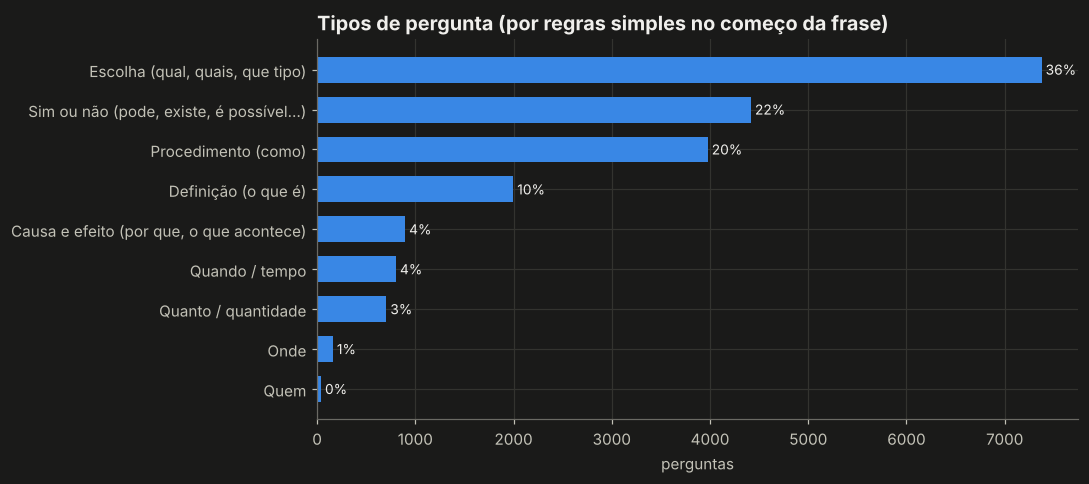

In [24]:
# A ORDEM IMPORTA: a pergunta fica no primeiro tipo cujo padrão casar.
# Os tipos específicos ("qual a época" = tempo) vêm antes do genérico ("qual" = escolha).
TIPOS = [
    ("Definição (o que é)",
     r"^(o )?que (é|são|significa|seria|vem a ser)\b|^qual (é )?(o )?(significado|conceito|definição)|^em que consiste"),
    ("Causa e efeito (por que, o que acontece)",
     r"^por ?que|^qual (é )?(a )?(razão|causa|motivo|efeito|influência|consequência)"
     r"|^(o )?que (causa|provoca|leva|explica|acontece|ocorre|influencia|afeta|interfere|determina|favorece)"
     r"|^o que (pode|deve) (acontecer|ocorrer)"),
    ("Quando / tempo",
     r"^quando|^durante quanto|^há quanto tempo|^até quando|^a partir de quando|^(por )?quanto tempo|^com que frequência"
     r"|^em que (época|período|fase|mês|meses|momento|estádio|estágio|idade|ano|horário)"
     r"|^qual (é )?(a |o )?(melhor )?(época|idade|período|momento|fase|estádio|estágio|horário|ciclo|intervalo|frequência)"),
    ("Quanto / quantidade",
     r"^quant[oa]s?\b|^que quantidade|^em quanto|^qual (é )?(a |o )?(quantidade|dose|dosagem|produtividade|rendimento"
     r"|espaçamento|densidade|população|custo|preço|valor|percentagem|porcentagem|temperatura|profundidade|distância"
     r"|tamanho|altura|peso|volume|teor|taxa|número|área|vazão|umidade|concentração|lâmina)"),
    ("Onde",
     r"^onde|^em que (local|locais|lugar|região|regiões|estado|estados|parte|partes|país|países|tipo de solo)"
     r"|^em quais (regiões|estados|locais|países)|^de onde"),
    ("Procedimento (como)",
     r"^como|^de que (forma|maneira|modo)|^qual (é )?(a |o )?(melhor )?(forma|maneira|modo|método|procedimento|técnica|sistema)"
     r"|^que (cuidados|medidas|métodos|procedimentos|práticas|técnicas|providências)|^(o )?que (fazer|se deve fazer|deve ser feito|pode ser feito)"),
    ("Quem", r"^quem"),
    ("Sim ou não (pode, existe, é possível...)",
     r"^(é possível|é verdade|é necessário|é preciso|é viável|é recomendável|é recomendado|é mais|é melhor|é correto"
     r"|existe|existem|há|pode|podem|poderia|deve|devem|compensa|vale a pena|convém|seria|tem|têm)\b"),
    ("Escolha (qual, quais, que tipo)",
     r"^(qual|quais|que|o que)\b|^(por|em|de|com|para|a|sob|entre|até|desde|dentre) (qual|quais|que)\b"),
]
def tipo_pergunta(p):
    p = p.lower().strip()
    # Uma pergunta pode ter introdução: "No plantio direto, qual é a melhor cobertura?".
    # Por isso testamos o começo de cada trecho separado por vírgula, ponto ou interrogação.
    trechos = [t.strip() for t in re.split(r"[,.;:?]", p) if t.strip()]
    # Palavras de ligação no começo ("E quais são...?") não mudam o tipo da pergunta
    trechos = [re.sub(r"^(e|mas|então|ou|afinal|enfim|em geral|nesse caso)\s+", "", t) for t in trechos]
    for nome, padrao in TIPOS:
        if any(re.search(padrao, t) for t in trechos):
            return nome
    # Nenhum trecho começa com palavra interrogativa (que, qual, como...): então a pergunta
    # só pode ser respondida com sim ou não. Ex.: "O sorgo pode ser usado na alimentação de aves?"
    return "Sim ou não (pode, existe, é possível...)"

pares = pares.assign(tipo_pergunta=pares["pergunta"].map(tipo_pergunta))
tp = pares["tipo_pergunta"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(tp.index, tp.values, color=[CINZA if t == "Outros" else AZUL for t in tp.index], height=0.65)
for i, v in enumerate(tp.values):
    ax.text(v, i, f" {v/len(pares):.0%}", va="center", fontsize=9)
ax.set_title("Tipos de pergunta (por regras simples no começo da frase)")
ax.set_xlabel("perguntas")
plt.tight_layout(); plt.show()

As **expressões regulares** (`re`) acima são padrões de texto: `^como` quer dizer "começa com
'como'" e `|` quer dizer "ou". Três ideias deixaram a classificação bem mais precisa:

- **Ordem:** os padrões específicos vêm antes dos genéricos. "Qual a época de plantio?" é sobre
  tempo, e por isso "Quando / tempo" é testado antes de "Escolha (qual)".
- **Trechos:** muitas perguntas têm uma introdução ("No plantio direto, qual é..."). Por isso
  cada trecho depois de uma vírgula ou ponto também é testado.
- **Sim ou não por eliminação:** se nenhum trecho começa com palavra interrogativa (que, qual,
  como, onde...), a pergunta só pode ser respondida com sim ou não ("O gesso corrige a acidez do
  solo?"). Assim, toda pergunta recebe um tipo e não sobra "Outros".

Ainda é uma regra simples e erra em alguns casos (perguntas duplas, como "O que é X? Qual a sua
composição?", ficam só com o primeiro tipo). Perguntas de **escolha (qual/quais)**, **sim ou não**
e **procedimento (como)** dominam. Seria bom o golden set ter essa mesma mistura.

## 8. Vocabulário

Quais palavras mais aparecem? Para a contagem ficar útil, removemos as **stopwords**: palavras muito
comuns que não dizem nada do assunto (de, a, o, que, para...).

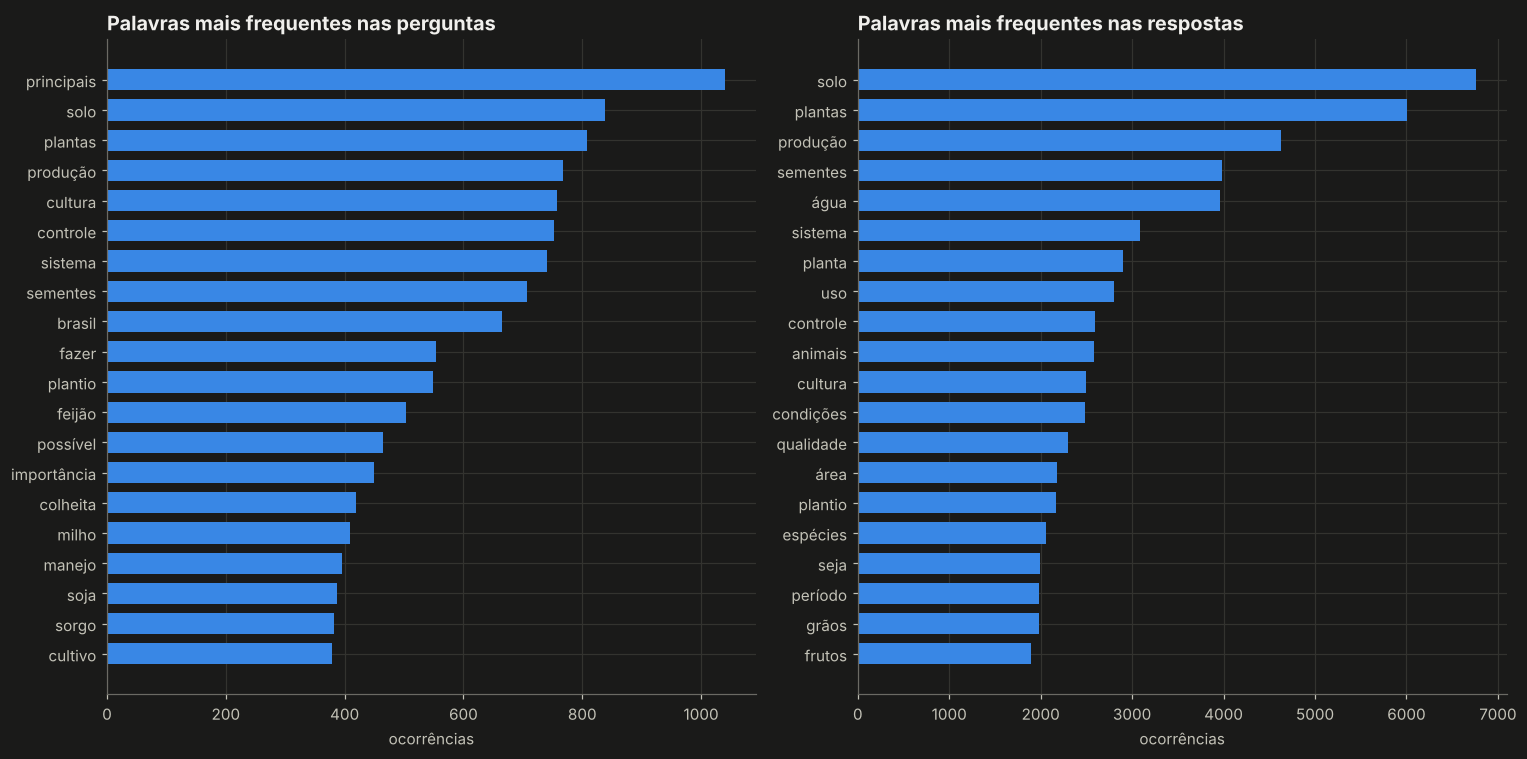

Vocabulário (palavras distintas, sem stopwords): perguntas = 10617; respostas = 39303


In [25]:
STOPWORDS = set('''
a à ao aos as às até com como da das de dela dele deles do dos e é em entre era essa esse esta
este eu foi for há isso isto já la lhe mais mas me mesmo muito na nas não nem no nos o os ou para
pela pelas pelo pelos por pode podem qual quais quando que se sem ser seu seus sua suas são também
te tem têm um uma umas uns vez cada sobre após onde ele ela eles elas está estão foram sendo sido
ter muitas muitos outra outras outro outros pois então assim ainda deve devem forma tipo além
bem caso menos maior menor quanto quantos sim
'''.split())

def palavras(texto):
    return [p for p in re.findall(r"[a-záàâãéêíóôõúç]+", texto.lower())
            if p not in STOPWORDS and len(p) > 2]

cont_perg = Counter(p for t in pares["pergunta"] for p in palavras(t))
cont_resp = Counter(p for t in pares["resposta"] for p in palavras(t))

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, cont, titulo in zip(axes, [cont_perg, cont_resp], ["perguntas", "respostas"]):
    top = pd.Series(dict(cont.most_common(20))).iloc[::-1]
    ax.barh(top.index, top.values, color=AZUL, height=0.7)
    ax.set_title(f"Palavras mais frequentes nas {titulo}")
    ax.set_xlabel("ocorrências")
plt.tight_layout(); plt.show()

print(f"Vocabulário (palavras distintas, sem stopwords): perguntas = {len(cont_perg)}; respostas = {len(cont_resp)}")

### 8.1 Palavras características de cada livro

A palavra mais frequente de um livro nem sempre é a mais *característica* dele ("produção" aparece
em todos). Uma ideia simples, parecida com o **TF-IDF**, é dar mais peso às palavras frequentes no
livro mas raras nos outros. Abaixo, as 8 palavras mais características de cada livro.

In [26]:
cont_livro = {c: Counter(p for t in g["texto"] for p in palavras(t))
              for c, g in pr.groupby("cultura")}
n_livros_com = Counter(p for cont in cont_livro.values() for p in cont)
N = len(cont_livro)

def caracteristicas(cultura, k=8):
    cont = cont_livro[cultura]
    total = sum(cont.values())
    score = {p: (n / total) * np.log(N / n_livros_com[p]) for p, n in cont.items() if n >= 5}
    return ", ".join(p for p, _ in sorted(score.items(), key=lambda x: -x[1])[:k])

pd.DataFrame({"palavras características": {c: caracteristicas(c) for c in sorted(cont_livro)}})

,palavras características
abacaxi,"abacaxi, abacaxizeiro, soca, fruto, filhote, smooth, cayenne, infestantes"
algodao,"algodao, algodoeiro, algodão, desfolhantes, fiação, cnpa, colorido, fibra"
amendoim,"amendoim, aflatoxinas, biodiesel, vagens, ecofisiologia, molecular, hypogaea, utds"
arroz,"arroz, quimigação, brusone, panículas, daninho, terras, inundação, soca"
banana,"banana, bananeira, sigatoka, pseudocaule, bananal, rizoma, panamá, prata"
bufalos,"bufalos, búfalos, búfalas, búfalo, bubalinos, búfala, recria, rebanho"
caju,"caju, cajueiro, castanha, amêndoas, amêndoa, pedúnculo, anão, castanhas"
caprinos-e-ovinos-de-corte,"ovinos, caprinos, caprina, peles, caprinocultura, ovina, cabritos, ovinocultura"
citros,"citros, microenxertia, cítricas, laranja, viróticas, pomar, tangerinas, tahiti"
coco,"coqueiro, coco, estipe, anão, thielaviopsis, resinose, coqueiros, coqueiral"


Isso funciona como uma "assinatura" de cada livro. Se duas assinaturas forem muito parecidas
(por exemplo, `gado-de-corte` e `gado-de-corte-no-pantanal`), é sinal de que o retriever pode
confundir os dois livros. Vale ter perguntas no golden set que testem essa fronteira.

## 9. Repetições

Perguntas iguais em livros diferentes podem confundir a avaliação: se a pergunta de teste aparece
em dois livros, qualquer um dos dois chunks pode ser a "resposta certa".

In [27]:
pares = pares.assign(pergunta_norm=pares["pergunta"].map(normalizar))
rep = pares[pares.duplicated("pergunta_norm", keep=False)]
grupos = rep.groupby("pergunta_norm").agg(vezes=("id", "size"),
                                          livros=("cultura", lambda s: ", ".join(sorted(set(s)))))
grupos = grupos.sort_values("vezes", ascending=False)

print(f"Perguntas (texto normalizado) que aparecem mais de uma vez: {len(grupos)}")
print(f"Total de chunks envolvidos: {len(rep)}")
print(f"Repetidas dentro do mesmo livro: {(rep.groupby('pergunta_norm')['cultura'].nunique() == 1).sum()}")
grupos.head(15)

Perguntas (texto normalizado) que aparecem mais de uma vez: 217
Total de chunks envolvidos: 487
Repetidas dentro do mesmo livro: 6


,vezes,livros
pergunta_norm,,
o que e fertirrigacao?,9,"abacaxi, amendoim, caju, coco, fruticultura-irrigada, mamona, manga, pera, uva"
o que e alelopatia?,6,"citros, hortas, manga, producao-organica-de-hortalicas, sementes, soja"
o que e uma cultivar?,6,"caju, coco, gergelim, hortas, manga, recursos-geneticos"
o que e controle biologico?,5,"fruticultura-irrigada, gergelim, milho, producao-organica-de-hortalicas, trigo"
o que e adubacao verde?,5,"banana, feijao-caupi, fruticultura-irrigada, hortas, producao-organica-de-hortalicas"
o que e biotecnologia?,4,"citros, fruticultura-irrigada, recursos-geneticos, trigo"
o que e uma variedade?,4,"caju, coco, hortas, manga"
o que e germoplasma?,4,"gergelim, recursos-geneticos, soja, trigo"
o que e fotoperiodo?,4,"gergelim, pequenas-frutas, pera, sementes"


In [28]:
resposta_norm = pares["resposta"].map(normalizar)
resp_rep = pares[resposta_norm.duplicated(keep=False)]
print(f"Chunks com resposta idêntica a de outro chunk: {len(resp_rep)}")
resp_rep.sort_values("resposta")[["id", "pergunta", "resposta"]].head(12)

Chunks com resposta idêntica a de outro chunk: 24


,id,pergunta,resposta
11586,mamona_2013_q494,Quando se descobriu a toxidez da mamona?,"A toxidez da mamona é conhecida desde a Antiguidade, tendo sido relatada pelos antigos hebreus, egípcios, persas, gr..."
11532,mamona_2013_q440,Quando se descobriu a toxidez da mamona?,"A toxidez da mamona é conhecida desde a Antiguidade, tendo sido relatada pelos antigos hebreus, egípcios, persas, gr..."
12718,milho_2013_q127,Por que a combinação do gesso com dejetos líquidos de animais é vantajosa?,"A vantagem deve-se à combinação do enxofre do gesso com o hidrogênio do esterco, evitando, assim, perdas por volatil..."
18790,sorgo_2015_q163,Por que a combinação do gesso com dejetos líquidos de animais é vantajosa no cultivo do sorgo orgânico?,"A vantagem deve-se à combinação do enxofre do gesso com o hidrogênio do esterco, evitando, assim, perdas por volatil..."
2340,banana_2013_q342,"Em que regiões foi relatada a ocorrência do vírus-do-mosaico-do-pepino (Cucumber mosaic virus, CMV)?",Esse vírus é encontrado em todo o Brasil e apresenta distribuição mundial.
2346,banana_2013_q348,"Em que regiões foi relatada a ocorrência do vírus-das-estrias-da-bananeira (Banana streak virus, BSV)?",Esse vírus é encontrado em todo o Brasil e apresenta distribuição mundial.
10299,maca_2013_q204,O que é evapotranspiração da cultura?,Evapotranspiração é a soma da água evaporada do solo e da água transpirada pelas plantas.
20364,uva_2013_q198,O que é evapotranspiração?,Evapotranspiração é a soma da água evaporada do solo e da água transpirada pelas plantas.
10918,mamao_2013_q323,Quais as espécies de nematoide-das-galhas mais agressivas ao mamoeiro?,Meloidogyne incognita e Meloidogyne javanica.
2428,banana_2013_q430,Quais as espécies de nematoides formadores de galha mais agressivos a bananeira?,Meloidogyne incognita e Meloidogyne javanica.


Respostas idênticas costumam ser respostas de referência ("Veja a resposta da pergunta X") ou
tabelas de notas reaproveitadas. Para o golden set, é melhor **evitar** perguntas com duplicatas,
ou aceitar qualquer um dos ids repetidos como certo.

## 10. O que ficou fora do corpus

Por decisão do orientador (14/11/2026), o corpus tem por enquanto só os pares que vêm de texto. O
`codigo/scripts/filtrar_chunks.py` tira três grupos do corpus completo:
- **Introduções:** o texto de apresentação de cada livro (não é pergunta-resposta).
- **Imagem transcrita:** perguntas cuja resposta foi completada com a transcrição de uma imagem
  (fórmula, gráfico, tabela, mapa). A transcrição foi feita com IA e não é reprodutível por script.
- **Imagem não transcrita:** perguntas cuja resposta remete a uma tabela ou figura que não está no
  texto (lista em `codigo/configs/ids_imagem_nao_transcrita.txt`).

Nada foi apagado: basta rodar o filtro com outras opções para voltar ao corpus completo.

In [29]:
def motivo(c):
    if c["tipo"] == "introducao":
        return "introdução"
    if c["conteudo_imagem"] == True:   # no pandas, quem não tem o campo fica com NaN
        return "imagem transcrita"
    return "imagem não transcrita"

saiu = completo[~completo["id_original"].isin(set(df["id_original"]))].copy()
saiu["motivo"] = saiu.apply(motivo, axis=1)

tabela_fora = (saiu.groupby("motivo")
               .agg(chunks=("id", "size"), perguntas_ou_trechos=("id_original", "nunique"))
               .reindex(["introdução", "imagem transcrita", "imagem não transcrita"]))
tabela_fora.loc["total"] = tabela_fora.sum()
tabela_fora = tabela_fora.astype(int)
print(f"Corpus completo: {len(completo):,} chunks  ->  corpus usado: {len(df):,} chunks".replace(",", "."))
tabela_fora

Corpus completo: 20.887 chunks  ->  corpus usado: 20.665 chunks


,chunks,perguntas_ou_trechos
motivo,,
introdução,96,96
imagem transcrita,121,113
imagem não transcrita,5,5
total,222,214


Por livro: as introduções saem de todos os livros (1 a 5 trechos cada). As perguntas com imagem estão
espalhadas por 32 livros, mas com poucas por livro; as que mais perderam foram sementes e suínos.

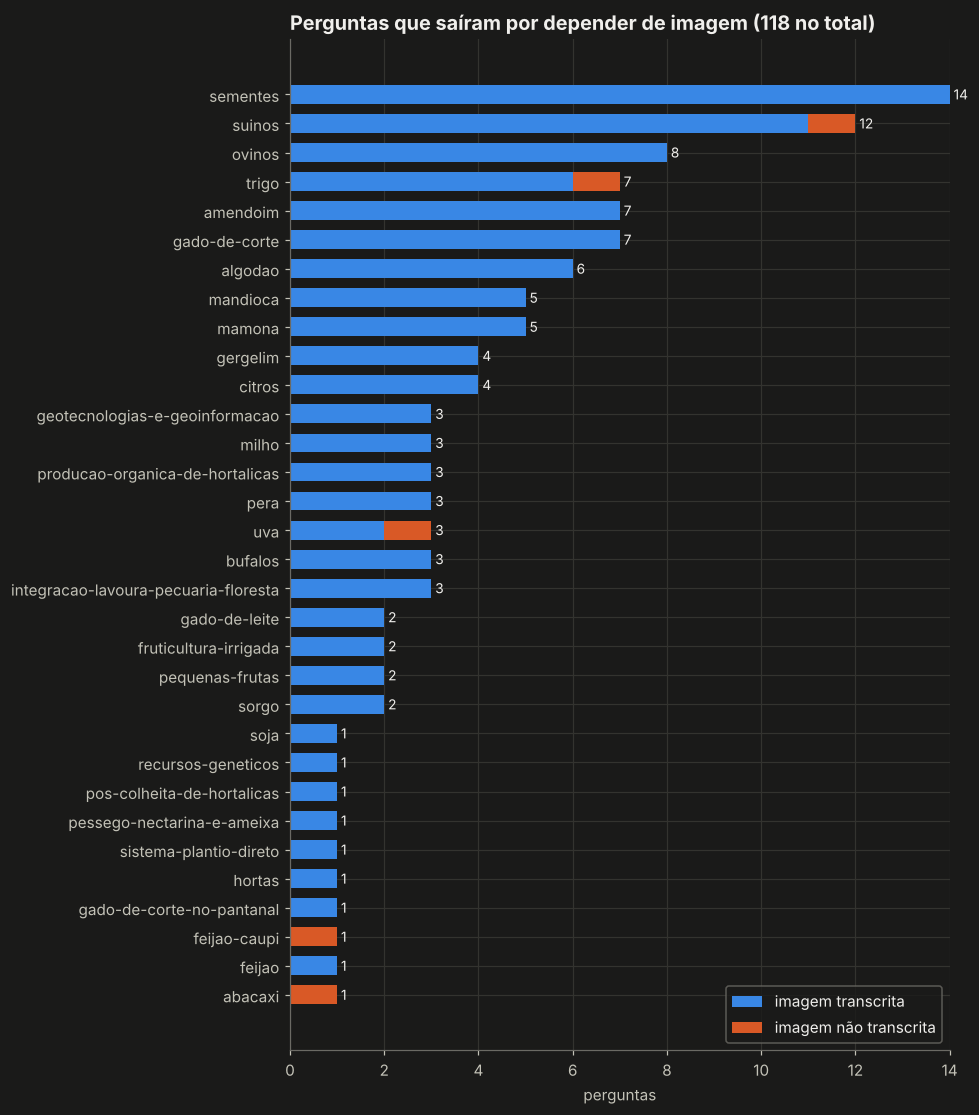

In [30]:
por_livro_fora = (saiu[saiu["motivo"] != "introdução"]
                  .drop_duplicates("id_original")
                  .groupby(["cultura", "motivo"]).size().unstack(fill_value=0))
por_livro_fora = por_livro_fora.loc[por_livro_fora.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(9, max(3, 0.32 * len(por_livro_fora))))
esquerda = np.zeros(len(por_livro_fora))
for col, cor in [("imagem transcrita", AZUL), ("imagem não transcrita", LARANJA)]:
    if col in por_livro_fora:
        ax.barh(por_livro_fora.index, por_livro_fora[col], left=esquerda, color=cor, height=0.65, label=col)
        esquerda += por_livro_fora[col].values
for i, v in enumerate(esquerda):
    ax.text(v, i, f" {int(v)}", va="center", fontsize=9)
ax.set_title(f"Perguntas que saíram por depender de imagem ({int(esquerda.sum())} no total)")
ax.set_xlabel("perguntas")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

As perguntas com imagem transcrita eram mais longas que as outras (mediana de 143 palavras no
`texto`, contra 86), porque a transcrição acrescentava texto. Mas são poucas perto do total (0,6% das
perguntas): o perfil do corpus (tamanhos, temas, tipos de pergunta) praticamente não muda.
Quando a transcrição puder ser feita de forma reprodutível, elas podem voltar, e seriam bons casos
de teste para perguntas cuja resposta está numa tabela ou fórmula.

## 11. Autores

Cada capítulo tem uma lista de autores. Isso não entra na busca, mas é útil para citar a fonte.

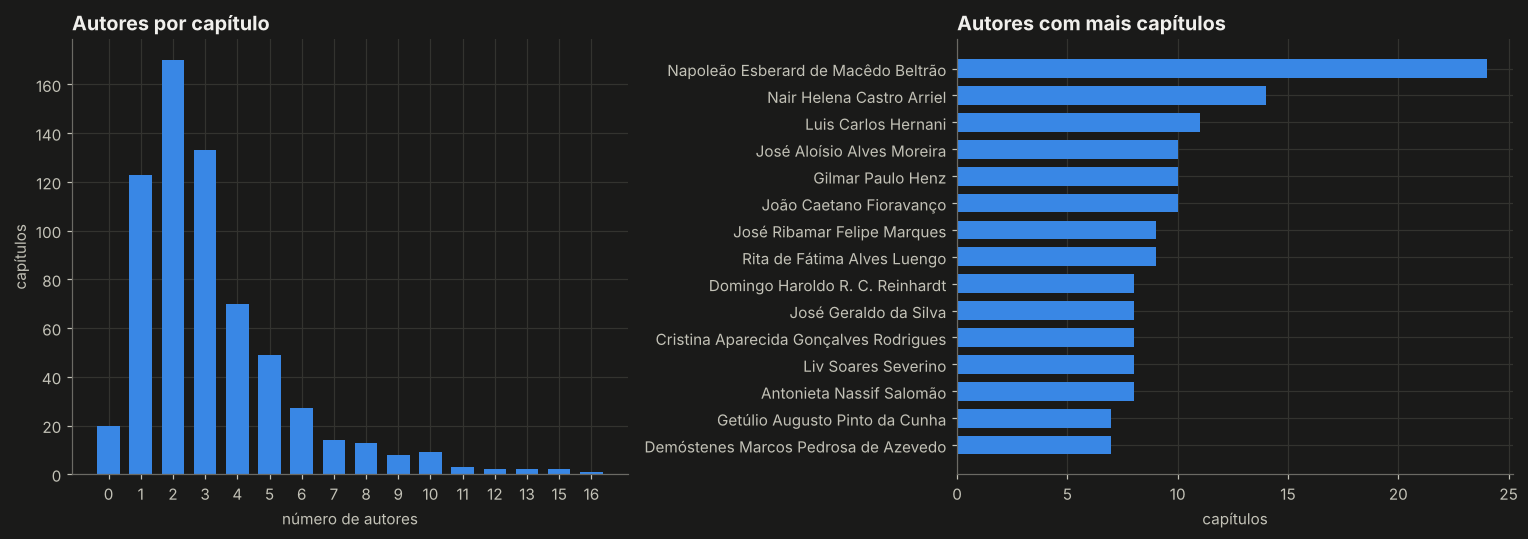

1.145 autores diferentes. Capítulos sem autor listado: 20
Livros com capítulos sem autor: ovinos, suinos


In [31]:
cap_aut = pares.drop_duplicates(["cultura", "capitulo"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
n_aut = cap_aut["n_autores"].value_counts().sort_index()
axes[0].bar(n_aut.index.astype(str), n_aut.values, color=AZUL, width=0.7)
axes[0].set_title("Autores por capítulo")
axes[0].set_xlabel("número de autores")
axes[0].set_ylabel("capítulos")

autores = Counter(a for lista in cap_aut["autores_capitulo"] for a in lista)
top = pd.Series(dict(autores.most_common(15))).iloc[::-1]
axes[1].barh(top.index, top.values, color=AZUL, height=0.7)
axes[1].set_title("Autores com mais capítulos")
axes[1].set_xlabel("capítulos")
plt.tight_layout(); plt.show()

sem_autor = cap_aut[cap_aut["n_autores"] == 0].groupby("cultura").size()
print(f"{len(autores):,} autores diferentes. Capítulos sem autor listado: {len(cap_aut[cap_aut['n_autores'] == 0])}".replace(",", "."))
print("Livros com capítulos sem autor:", ", ".join(sem_autor.index))

## 12. Resumo dos achados

A célula abaixo junta os números principais numa tabela só.

In [32]:
resumo = pd.Series({
    "Chunks no total": len(df),
    "Livros": df["cultura"].nunique(),
    "Perguntas originais": len(pares),
    "Chunks no corpus completo (antes do filtro)": len(completo),
    "Chunks fora do corpus (filtro)": len(saiu),
    "Perguntas divididas em 2+ chunks": int((pares["total_partes"] > 1).sum()),
    "Mediana de palavras por chunk": int(pr["texto_palavras"].median()),
    f"Máximo de tokens por chunk ({FONTE_TOKENS})": int(pr["tokens"].max()),
    "Capítulos (livro + capítulo)": len(cap_aut),
    "Perguntas repetidas (texto igual)": len(grupos),
    "Livros com pergunta faltando (fora as filtradas)": len(problemas),
})
resumo.to_frame("valor")

,valor
Chunks no total,20665
Livros,41
Perguntas originais,20381
Chunks no corpus completo (antes do filtro),20887
Chunks fora do corpus (filtro),222
Perguntas divididas em 2+ chunks,267
Mediana de palavras por chunk,86
Máximo de tokens por chunk (tokenizador real do multilingual-e5-small),512
Capítulos (livro + capítulo),646
Perguntas repetidas (texto igual),217


**Principais conclusões**

1. **O corpus é só texto.** Depois do filtro de 14/11/2026, são 20.665 chunks (20.381 perguntas),
   todos pergunta-resposta. Saíram 222 chunks do corpus completo: 96 introduções, 113 perguntas com
   imagem transcrita (121 chunks) e 5 perguntas que dependiam de imagem não transcrita.
2. **Os dados estão limpos.** Não há resposta vazia, todo chunk tem `texto`, e, contando as
   perguntas filtradas, 40 dos 41 livros têm as 500 perguntas numeradas certinho. A única falha de
   extração é a **pergunta 383 de búfalos**.
3. **O corpus é equilibrado:** cada livro tem entre 492 e 559 chunks, então nenhuma cultura domina o
   índice.
4. **Os chunks são curtos:** a mediana é de cerca de 86 palavras, bem abaixo do limite de 512
   tokens. Só 1,3% das perguntas (267) precisou ser dividida.
5. **A maioria dos livros é de 2013.** Recomendações podem estar desatualizadas, e vale mostrar o
   ano da fonte na resposta do sistema.
6. Os temas mais frequentes são **pragas, doenças e plantas daninhas** (17%), **plantio, manejo e
   sistemas de produção** (15%) e **animais** (14%). Só 2% das perguntas ficaram sem tema. Nos tipos
   de pergunta dominam **escolha (qual/quais)** (36%), **sim ou não** (22%) e **como** (20%).
7. **Existem perguntas repetidas** entre livros (e algumas respostas idênticas). No golden set,
   evite essas perguntas ou aceite qualquer um dos ids como certo.

**Próximos passos sugeridos**
- Conferir a pergunta 383 de búfalos no livro original.
- Montar o golden set seguindo a proporção de temas e tipos de pergunta vista aqui.
- Testar se livros parecidos (gado de corte x gado de corte no Pantanal, hortas x hortaliças) se
  confundem na busca.